In [1]:
from glob import glob
from itertools import product
import pandas as pd
import json

In [2]:
profile_ordering = sorted([f"profile_{i}.csv" for i in range(100)])

In [3]:
all_files = glob("../stats/bt_proportionality/*.json")
df_list = []
for path in all_files:

    with open(path, "r") as f:
        data = json.load(f)

    rows = []
    for file_path, methods in data.items():
        for method, vals in methods.items():
            rows.append({
                "file": file_path,
                "method": method,
                "expected_proportion": vals.get("expected_proportion"),
                "observed_proportion": vals.get("observed_proportion"),
            })

    df_list.append(pd.DataFrame(rows))

prop_df = pd.concat(df_list, ignore_index=True)
prop_df["file"] = prop_df["file"].str.split("/data/").str[1]
# prop_df["prop"] = 1 - abs(prop_df["observed_proportion"] - prop_df["expected_proportion"])
# FIXME: This is just an experiment for disprop
prop_df["prop"] = prop_df["observed_proportion"] - prop_df["expected_proportion"]
prop_df.drop(columns=["expected_proportion", "observed_proportion"], inplace=True)
prop_df.query("method != 'random'", inplace=True)
prop_df.set_index(["method", "file"], inplace=True)
prop_df

,,prop
method,file,
borda,"preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv",-0.166667
3-approval,"preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv",0.166667
2-approval,"preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv",0.166667
plurality,"preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv",0.166667
stv,"preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv",0.166667
...,...,...
3-approval,"preference_profiles/05_05/b_proportion_0.9__ALPHA_(2.00,2.00,2.00,2.00)__COHESION_(0.70,0.70)/profile_99.csv",0.111402
2-approval,"preference_profiles/05_05/b_proportion_0.9__ALPHA_(2.00,2.00,2.00,2.00)__COHESION_(0.70,0.70)/profile_99.csv",0.111402
plurality,"preference_profiles/05_05/b_proportion_0.9__ALPHA_(2.00,2.00,2.00,2.00)__COHESION_(0.70,0.70)/profile_99.csv",0.111402


In [4]:
voting_rule_names = [
    "borda",
    "3-approval",
    "2-approval",
    "plurality",
    "stv",
    "ranked-pairs",
]

In [5]:
n_voters = 15_000
n_samples = 100

b_bloc_proportions = [0.5, 0.6, 0.7, 0.8, 0.9]
alpha_combinations = [
    (1, 1, 1, 1),
    (0.5, 0.5, 0.5, 0.5),
    (2, 2, 2, 2),
    (1, 0.5, 1, 0.5),
    (1, 2, 1, 2),
    (0.5, 1, 0.5, 1),
    (2, 1, 2, 1),
]
cohesion_combinations = [
    (0.7, 0.7),
    (0.7, 0.9),
    (0.9, 0.7),
    (0.9, 0.9),
]
candidate_count_combinations = [
    (2, 6),
    (4, 4),
    (6, 2),
    (2, 8),
    (5, 5),
    (8, 2),
]


output_base_dir = "preference_profiles"
iia_data_base_dir = "../stats/bt_2_bloc_profile_stats/3_seats/sigma_IIA"


df_list = []
for (n_a_cands, n_b_cands), (aa_alpha, ab_alpha, ba_alpha, bb_alpha), (a_cohesion, b_cohesion), b_proportion, voting_rule_name in product(
    candidate_count_combinations,
    alpha_combinations,
    cohesion_combinations,
    b_bloc_proportions,
    voting_rule_names
):
    profile_pattern = (
        f"{output_base_dir}/"
        f"{n_a_cands:02d}_{n_b_cands:02d}/"
        f"b_proportion_{b_proportion}"
        f"__ALPHA_({aa_alpha:.2f},{ab_alpha:.2f},{ba_alpha:.2f},{bb_alpha:.2f})"
        f"__COHESION_({a_cohesion:.2f},{b_cohesion:.2f})/"
    )

    iia_pattern = (
        f"{iia_data_base_dir}/"
        f"{n_a_cands+n_b_cands:02d}/"
        f"{voting_rule_name}/"
        "METRIC_sigma_IIA__VARIANT_average__INTERP_None"
        f"__NCANDS_({n_a_cands:02d}_{n_b_cands:02d})"
        "__SEATS_3"
        f"__BPROP_{b_proportion:0.1f}"
        f"__ALPHA_({aa_alpha:0.2f},{ab_alpha:0.2f},{ba_alpha:0.2f},{bb_alpha:0.2f})"
        f"__COHESION_({a_cohesion:.2f},{b_cohesion:.2f})"
        f"__TYPE_{voting_rule_name}"
        "__TIEBREAK_lex.json"
    )    

    with open(iia_pattern, "r") as f:
        iia_data = json.load(f)
    df_data = []
    for file, value in zip(profile_ordering, iia_data):
        df_data.append({
            "file": f"{profile_pattern}{file}",
            "method": voting_rule_name,
            "sigma_IIA": value,
        })

    df_list.append(pd.DataFrame(df_data))


iia_df = pd.concat(df_list, ignore_index=True)
iia_df.set_index(["method", "file"], inplace=True)
iia_df

sigma_IIA
method       file                                                         
borda        preference_profiles/02_06/b_proportion_0.5__ALP...   0.994048
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.976190
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.976190
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.988095
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.946429
...                                                                    ...
ranked-pairs preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000

[504000 rows x 1 columns]

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
rule_color_map = {
    "borda": "#1460bc",  # lightblue
    "3-approval": "#8cb500",  # applegreen
    "2-approval": "#218c21",  # forestgreen
    "plurality": "#d11942",  # alizarin
    "stv": "#ffc40c",  # mikadoyellow
    "ranked-pairs": "#ffb7c4",  # cherryblossompink
    "random": "#707f8e",  # slategray
}

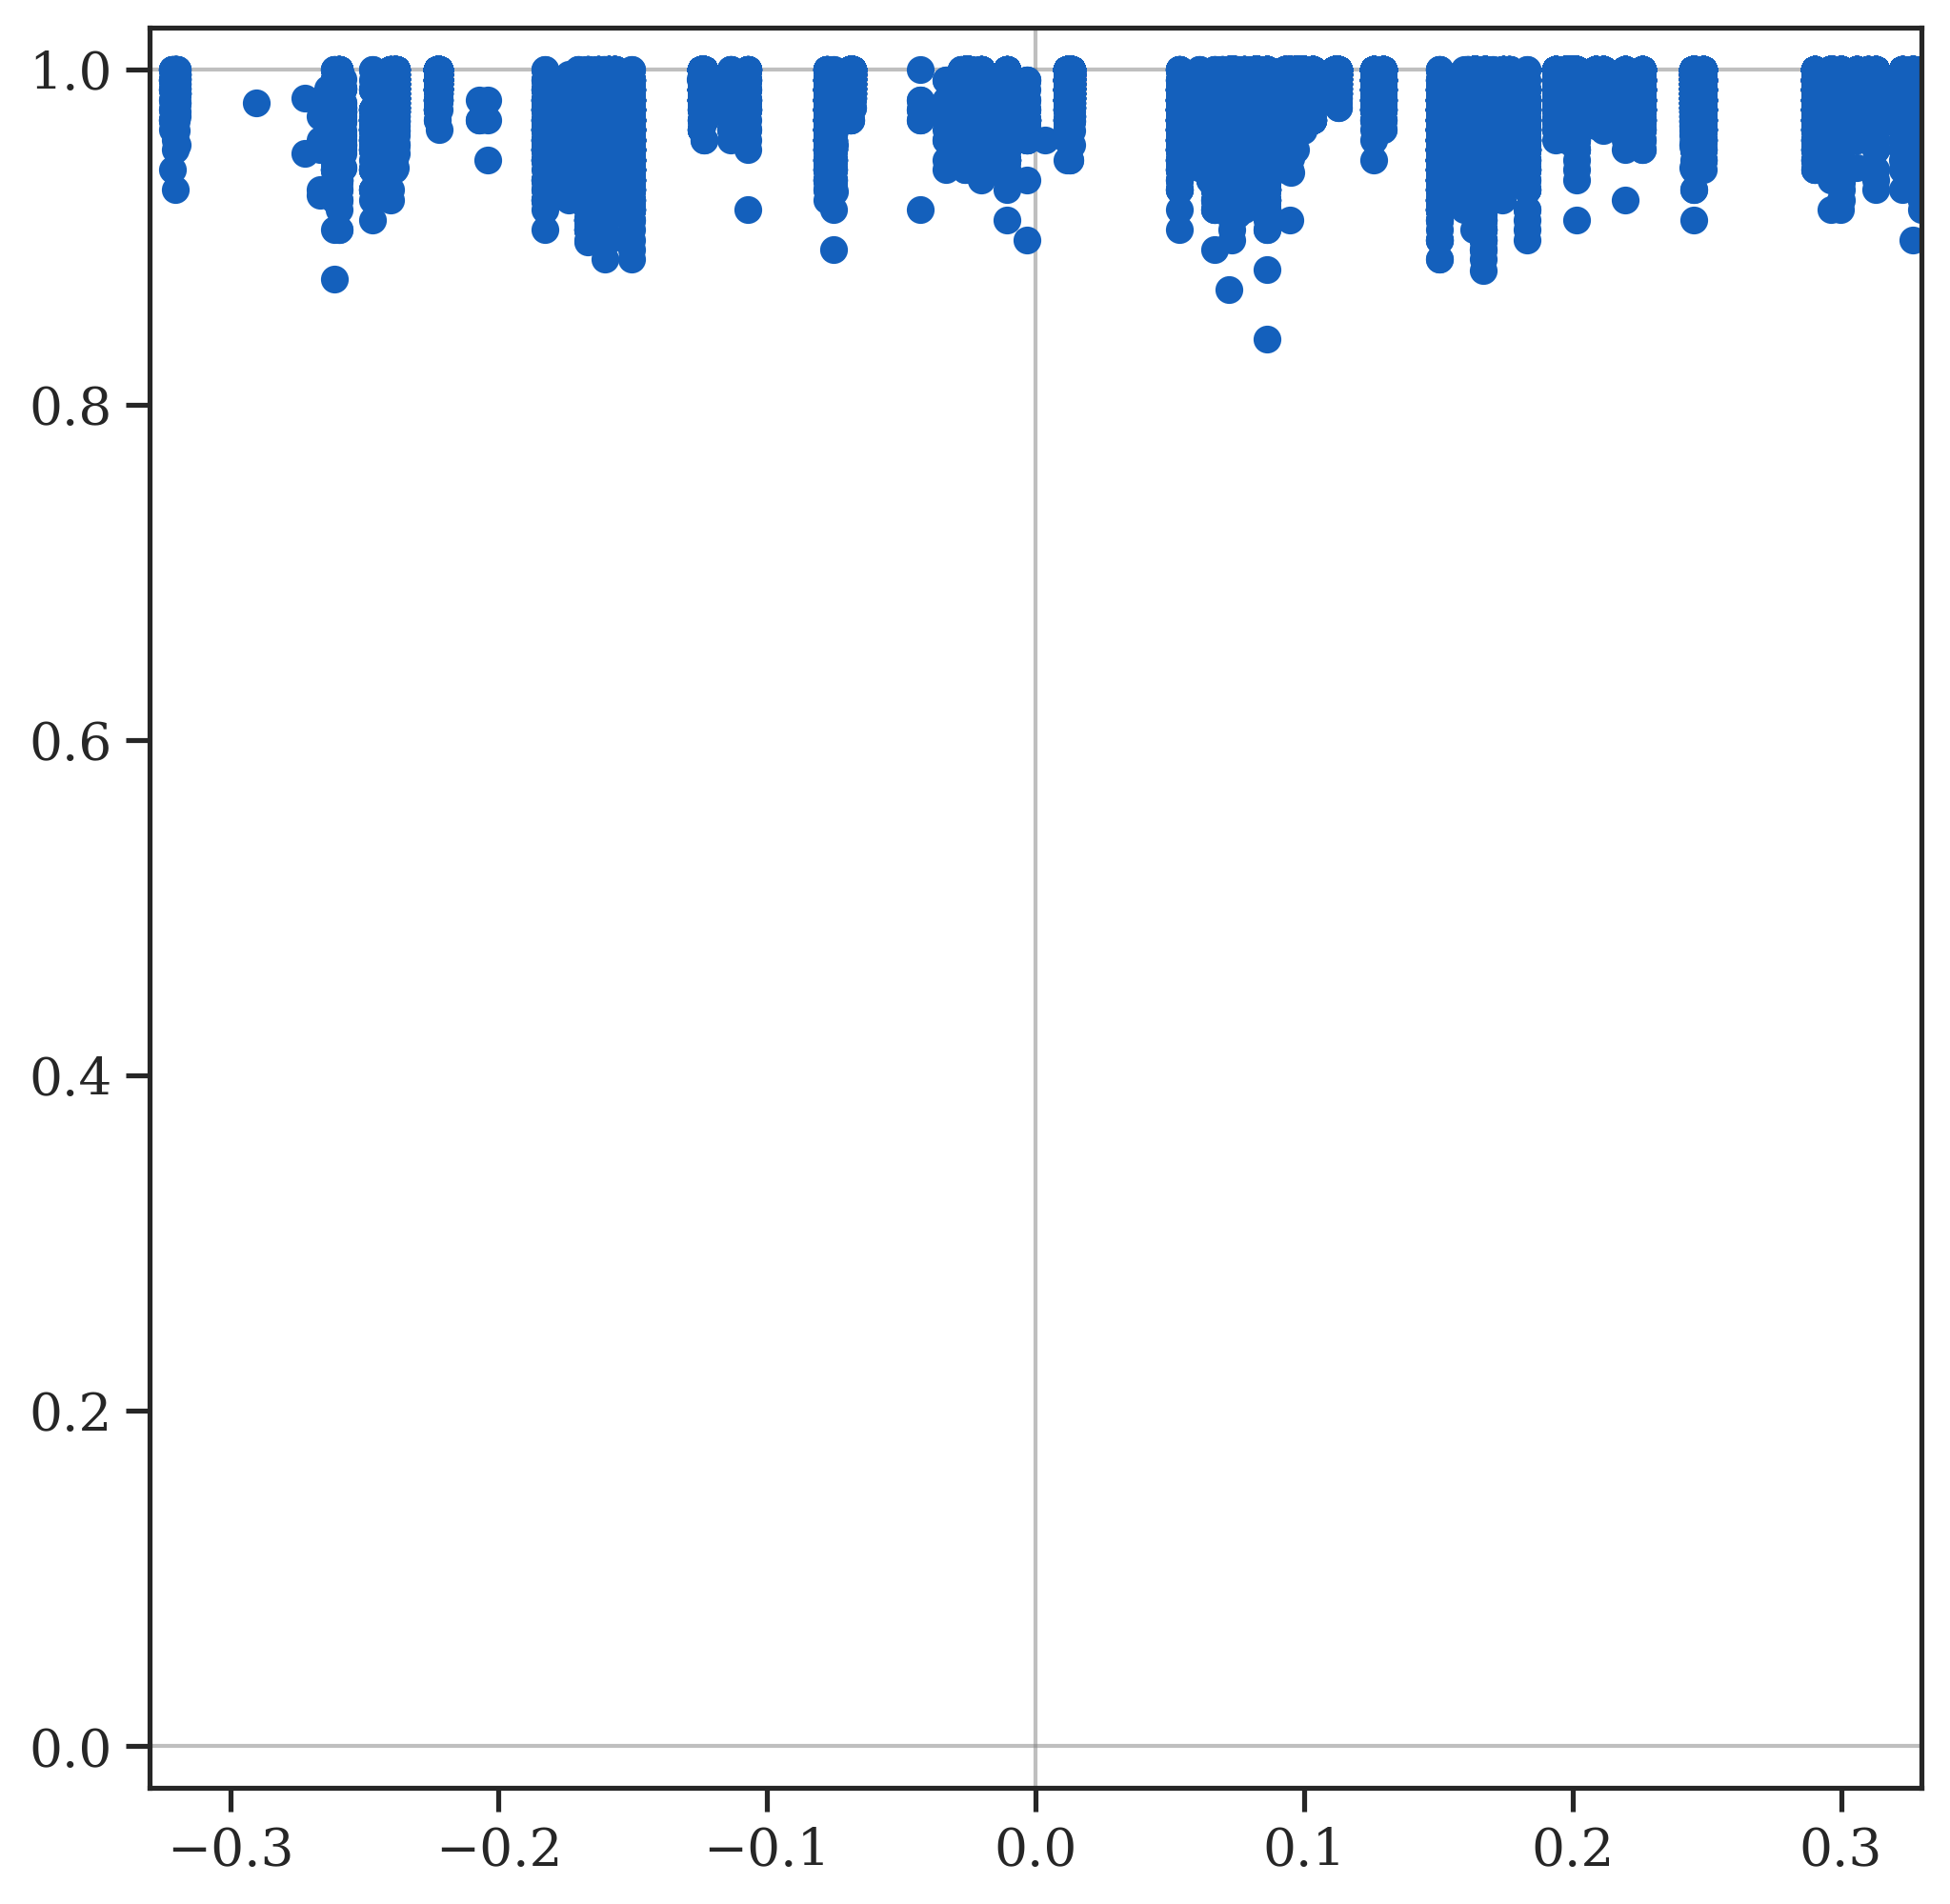

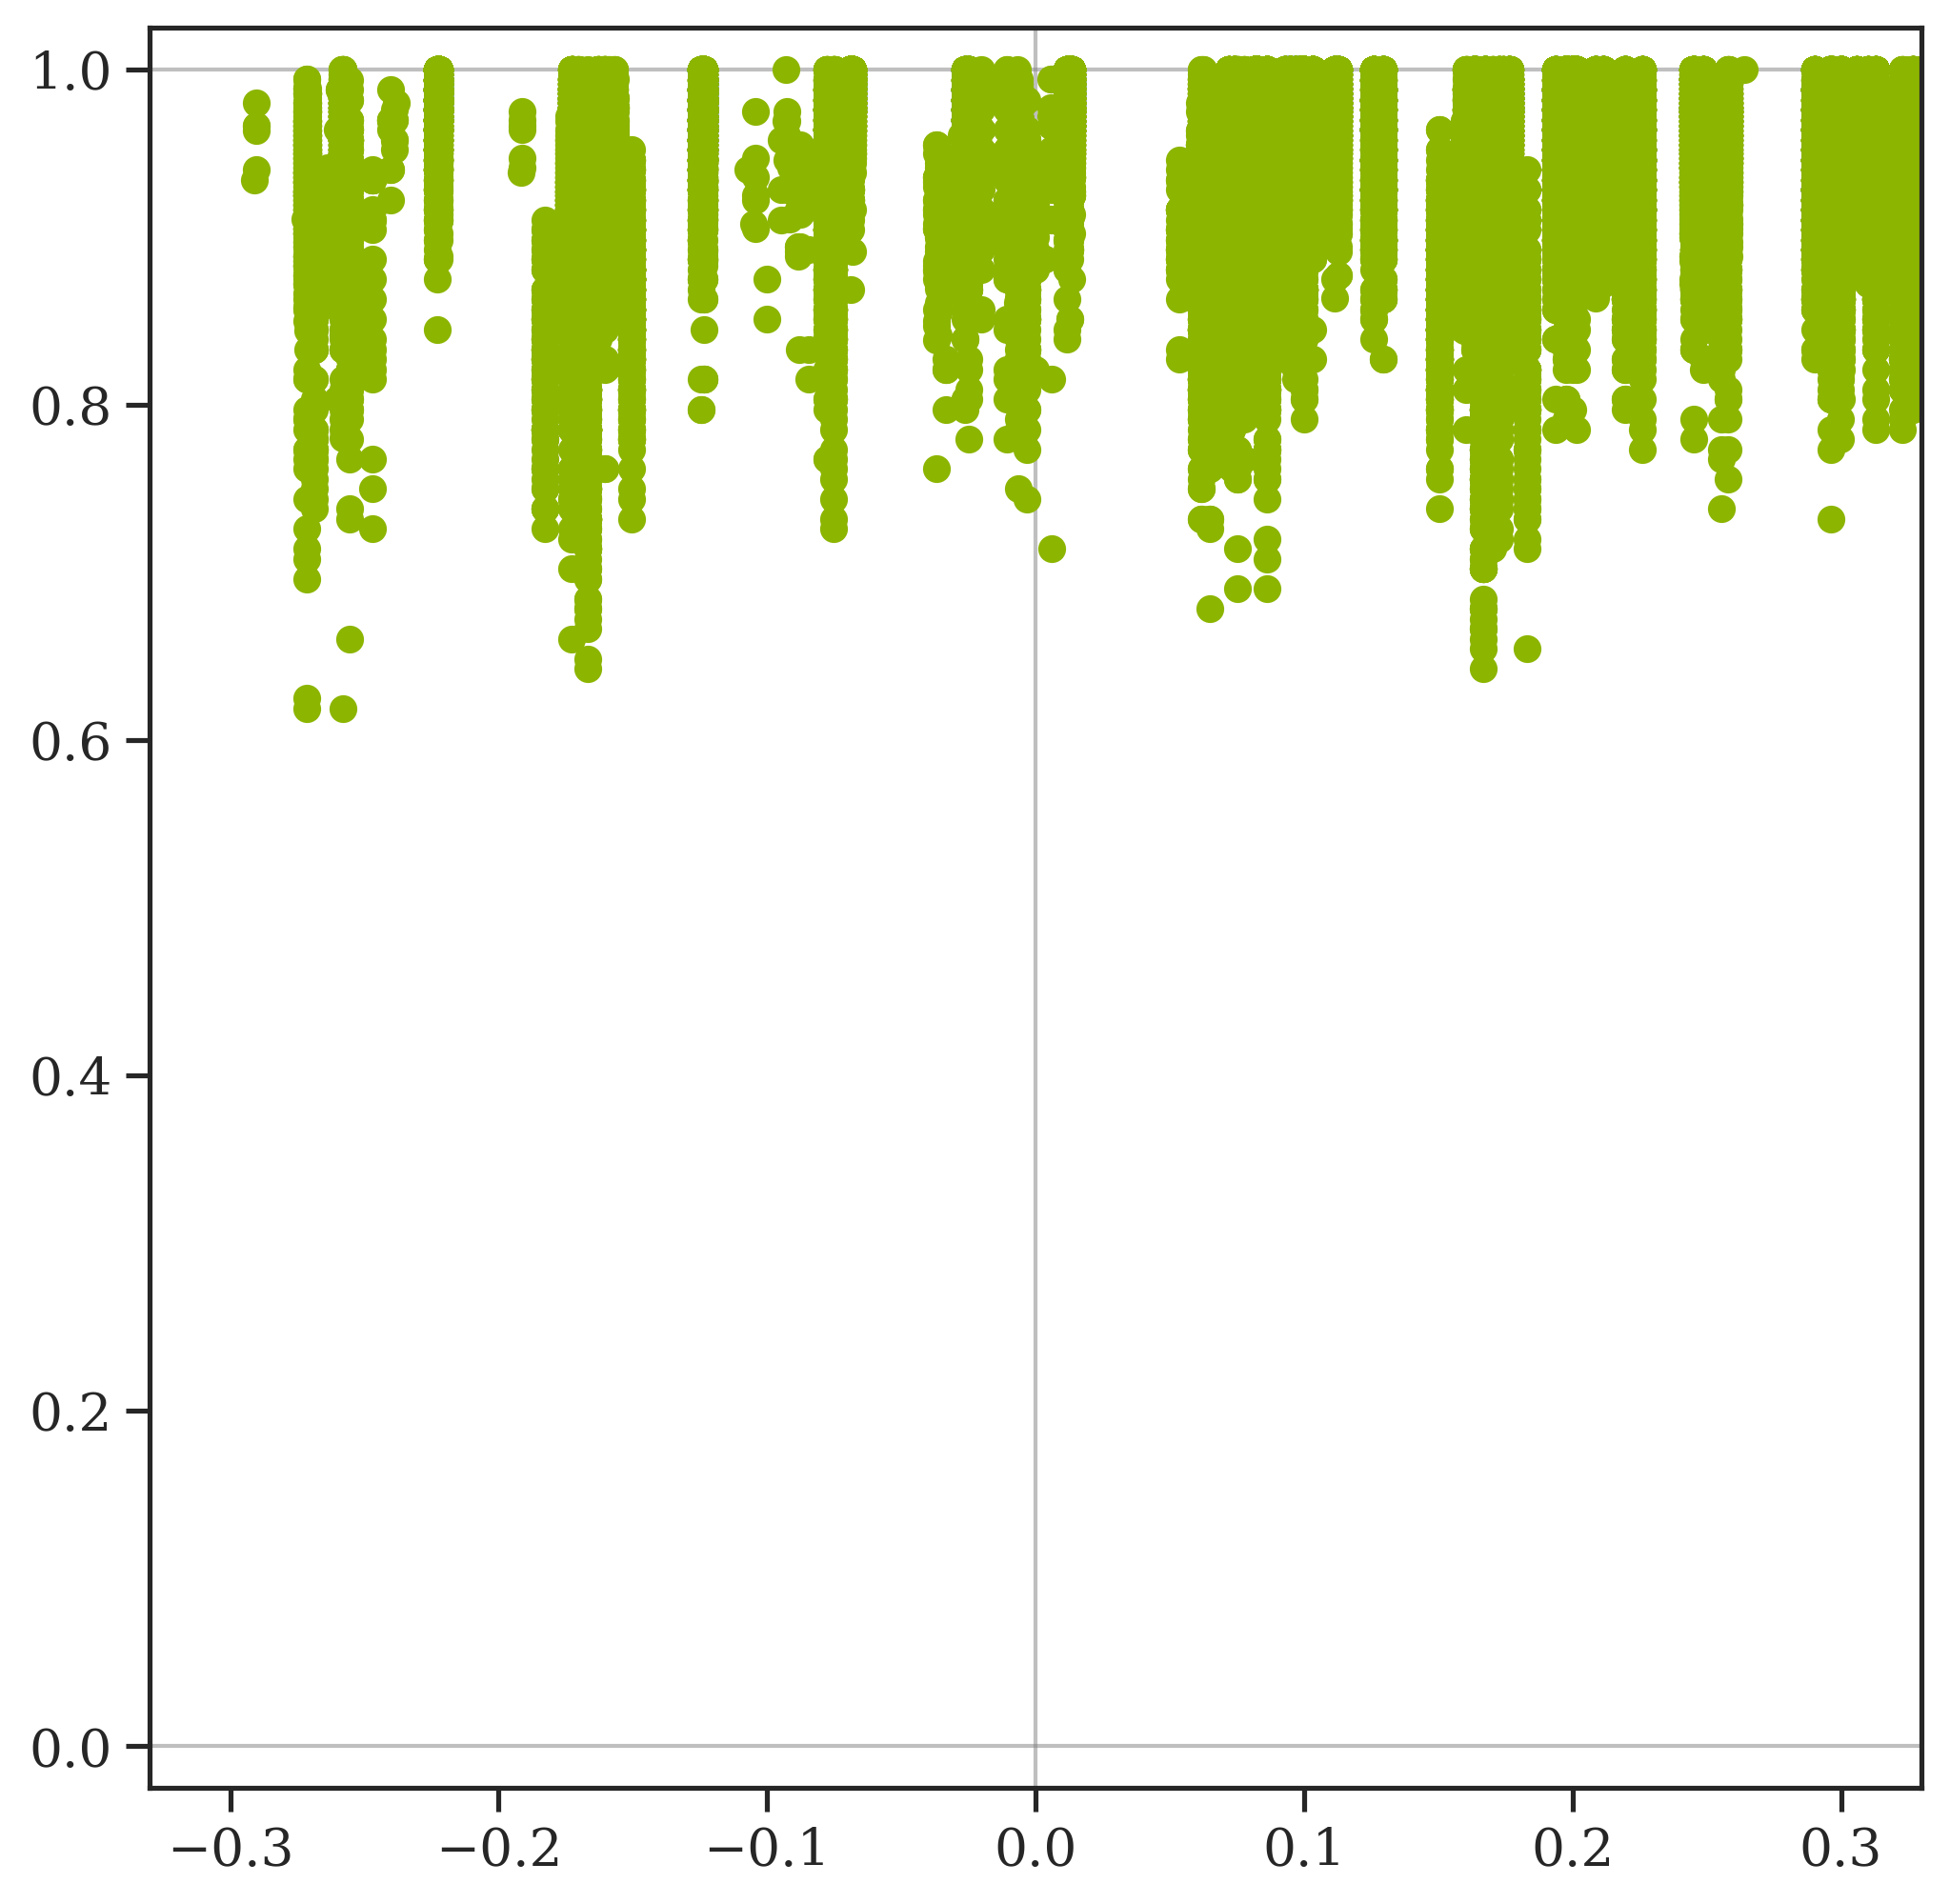

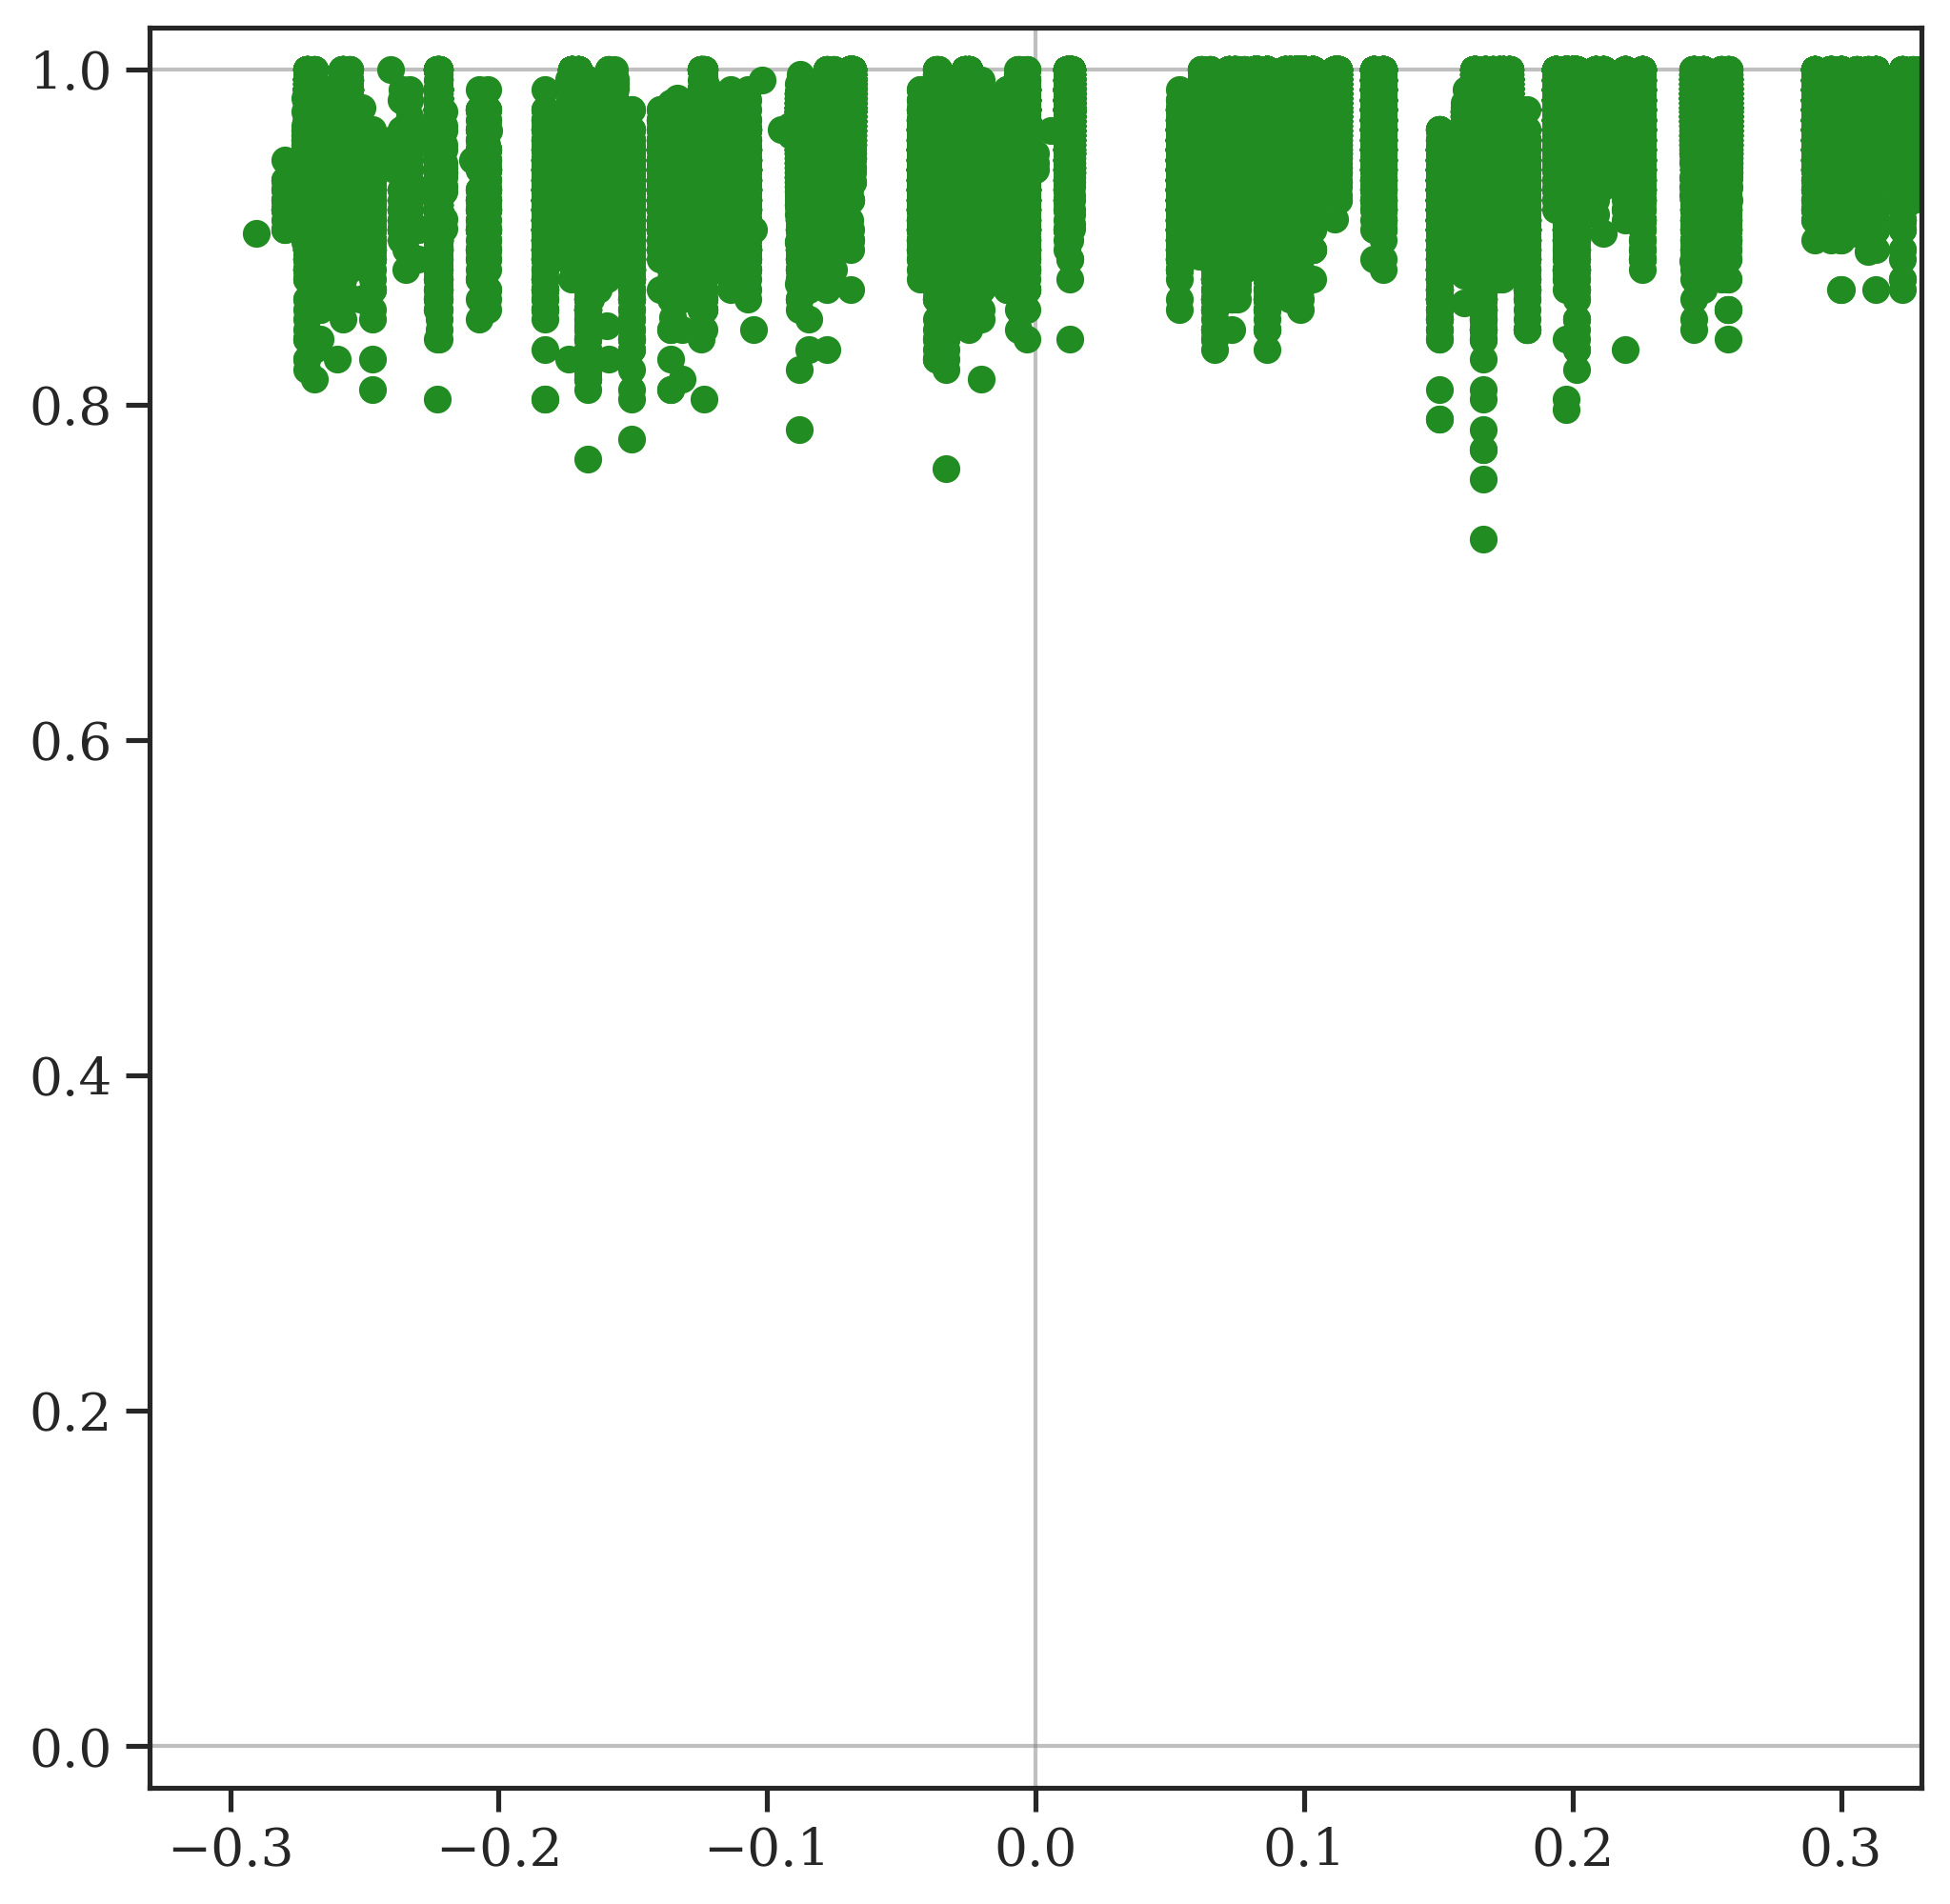

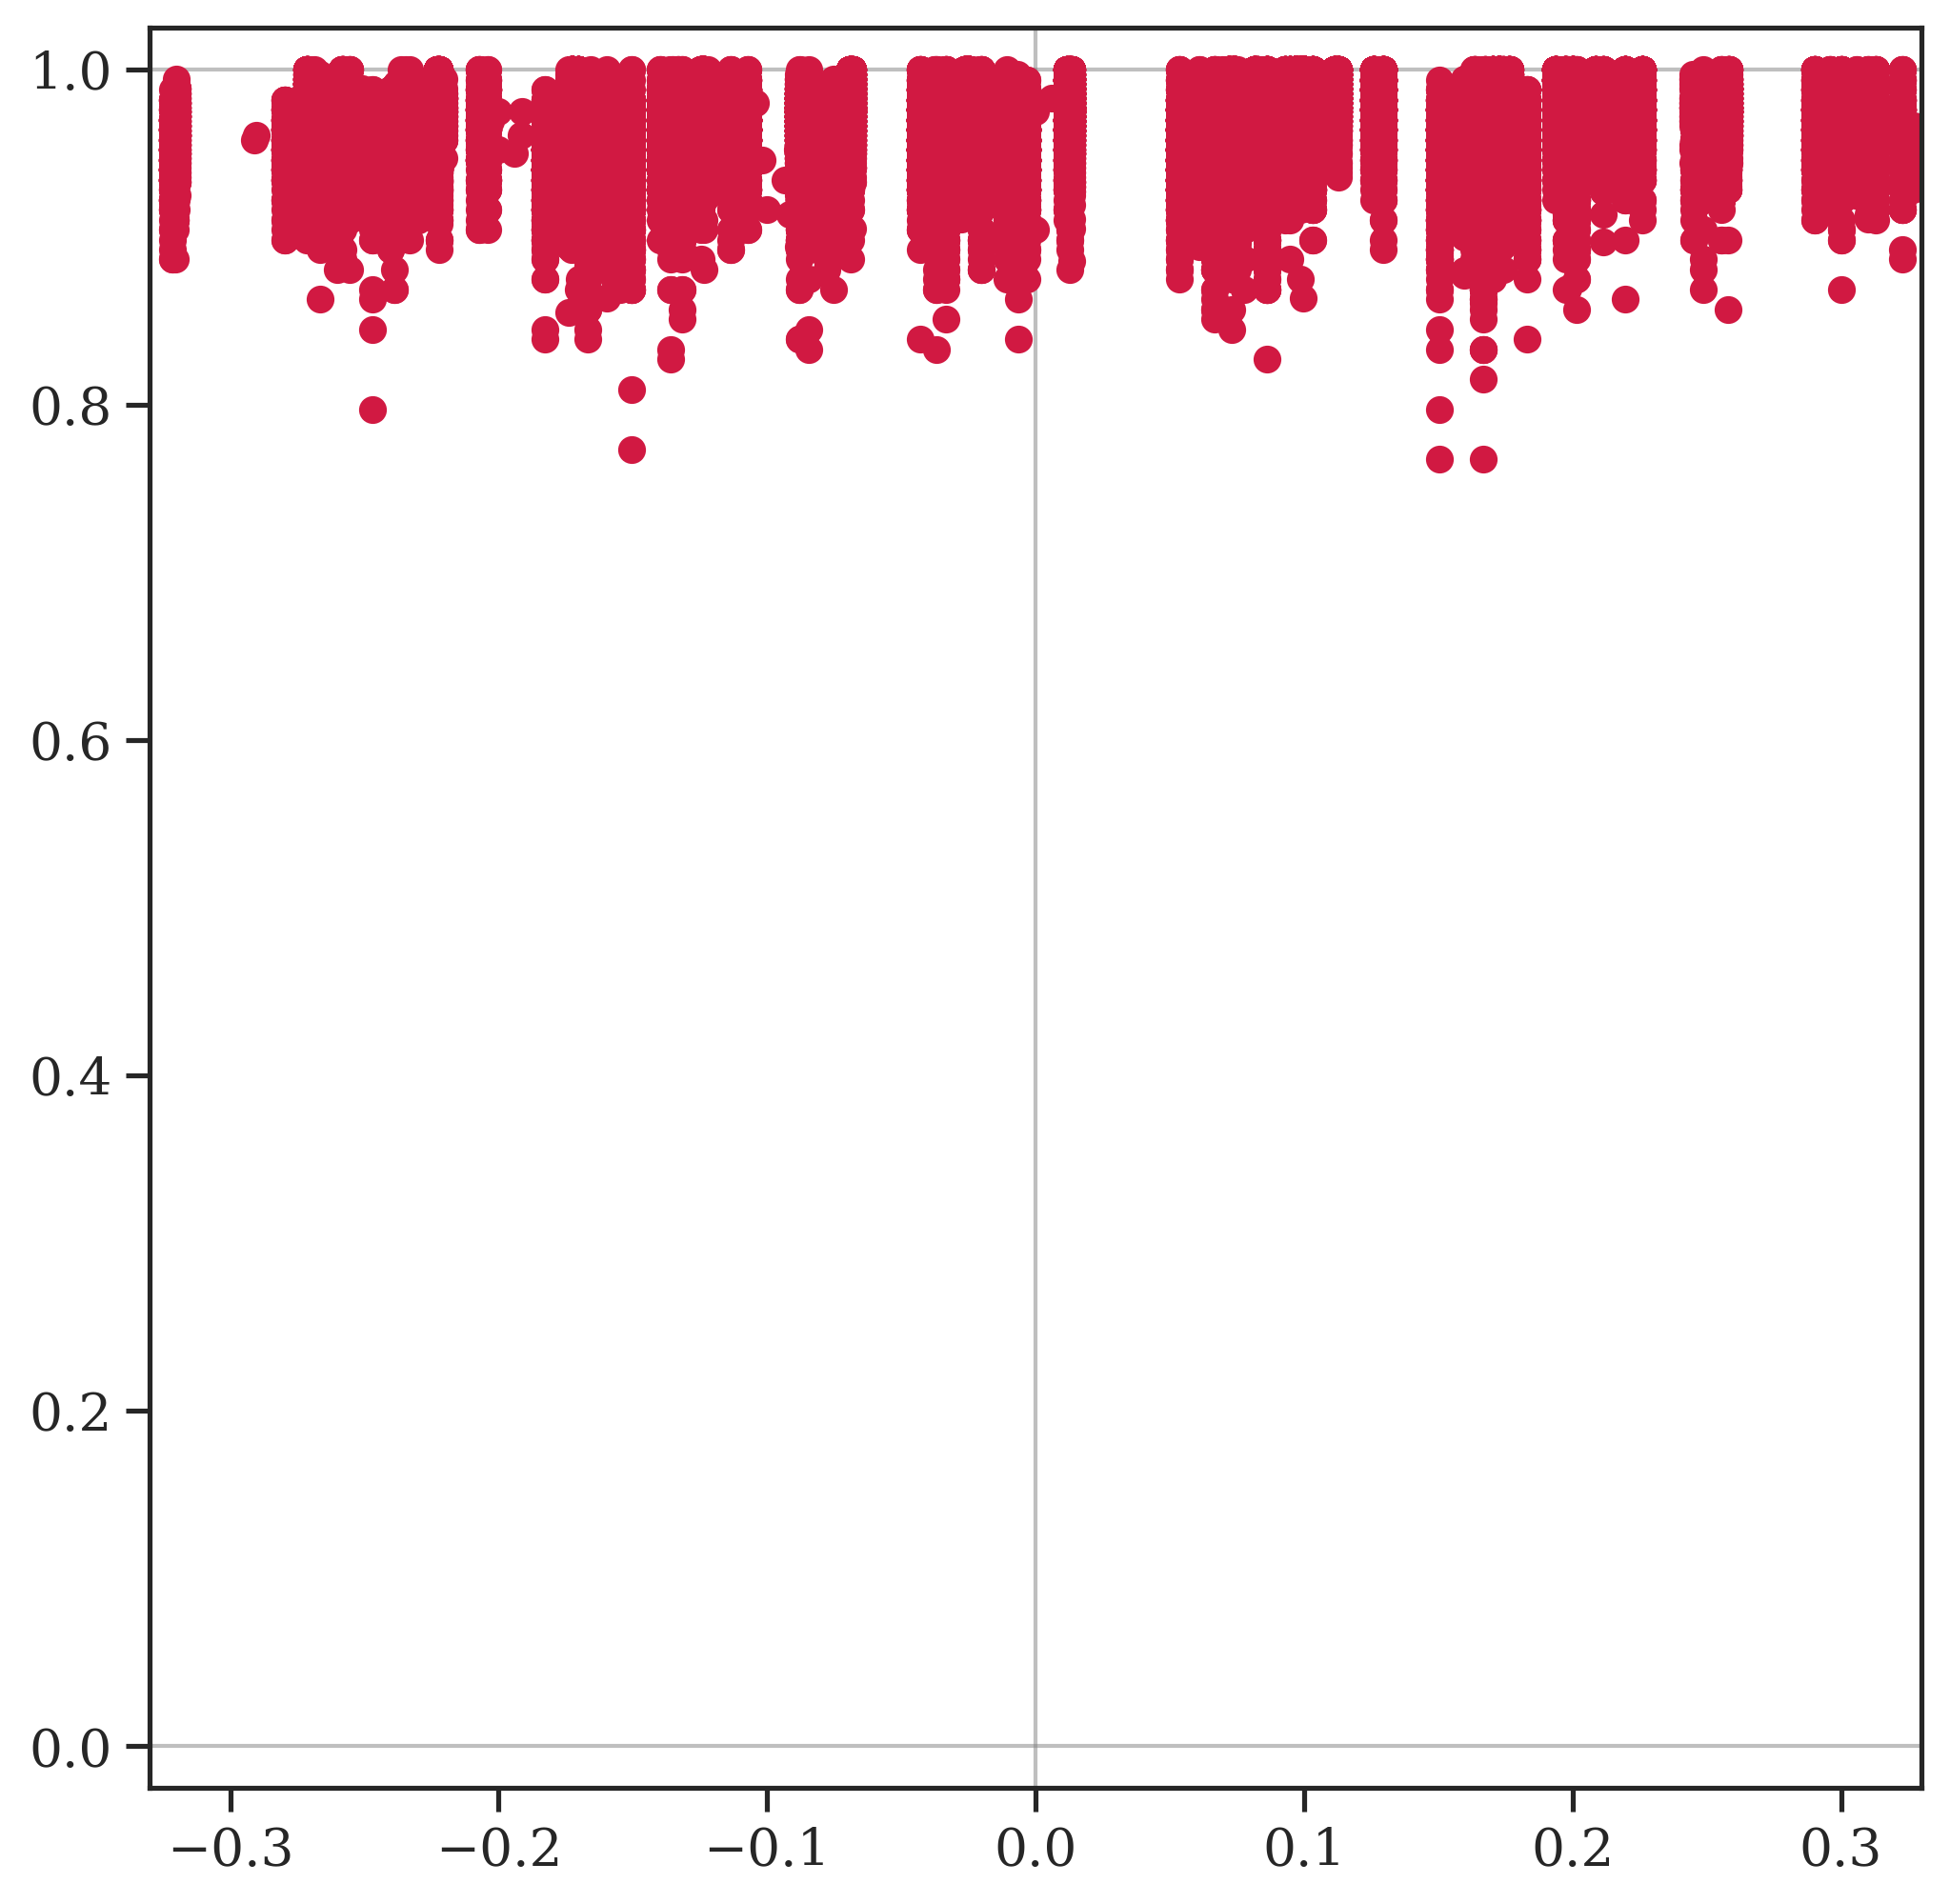

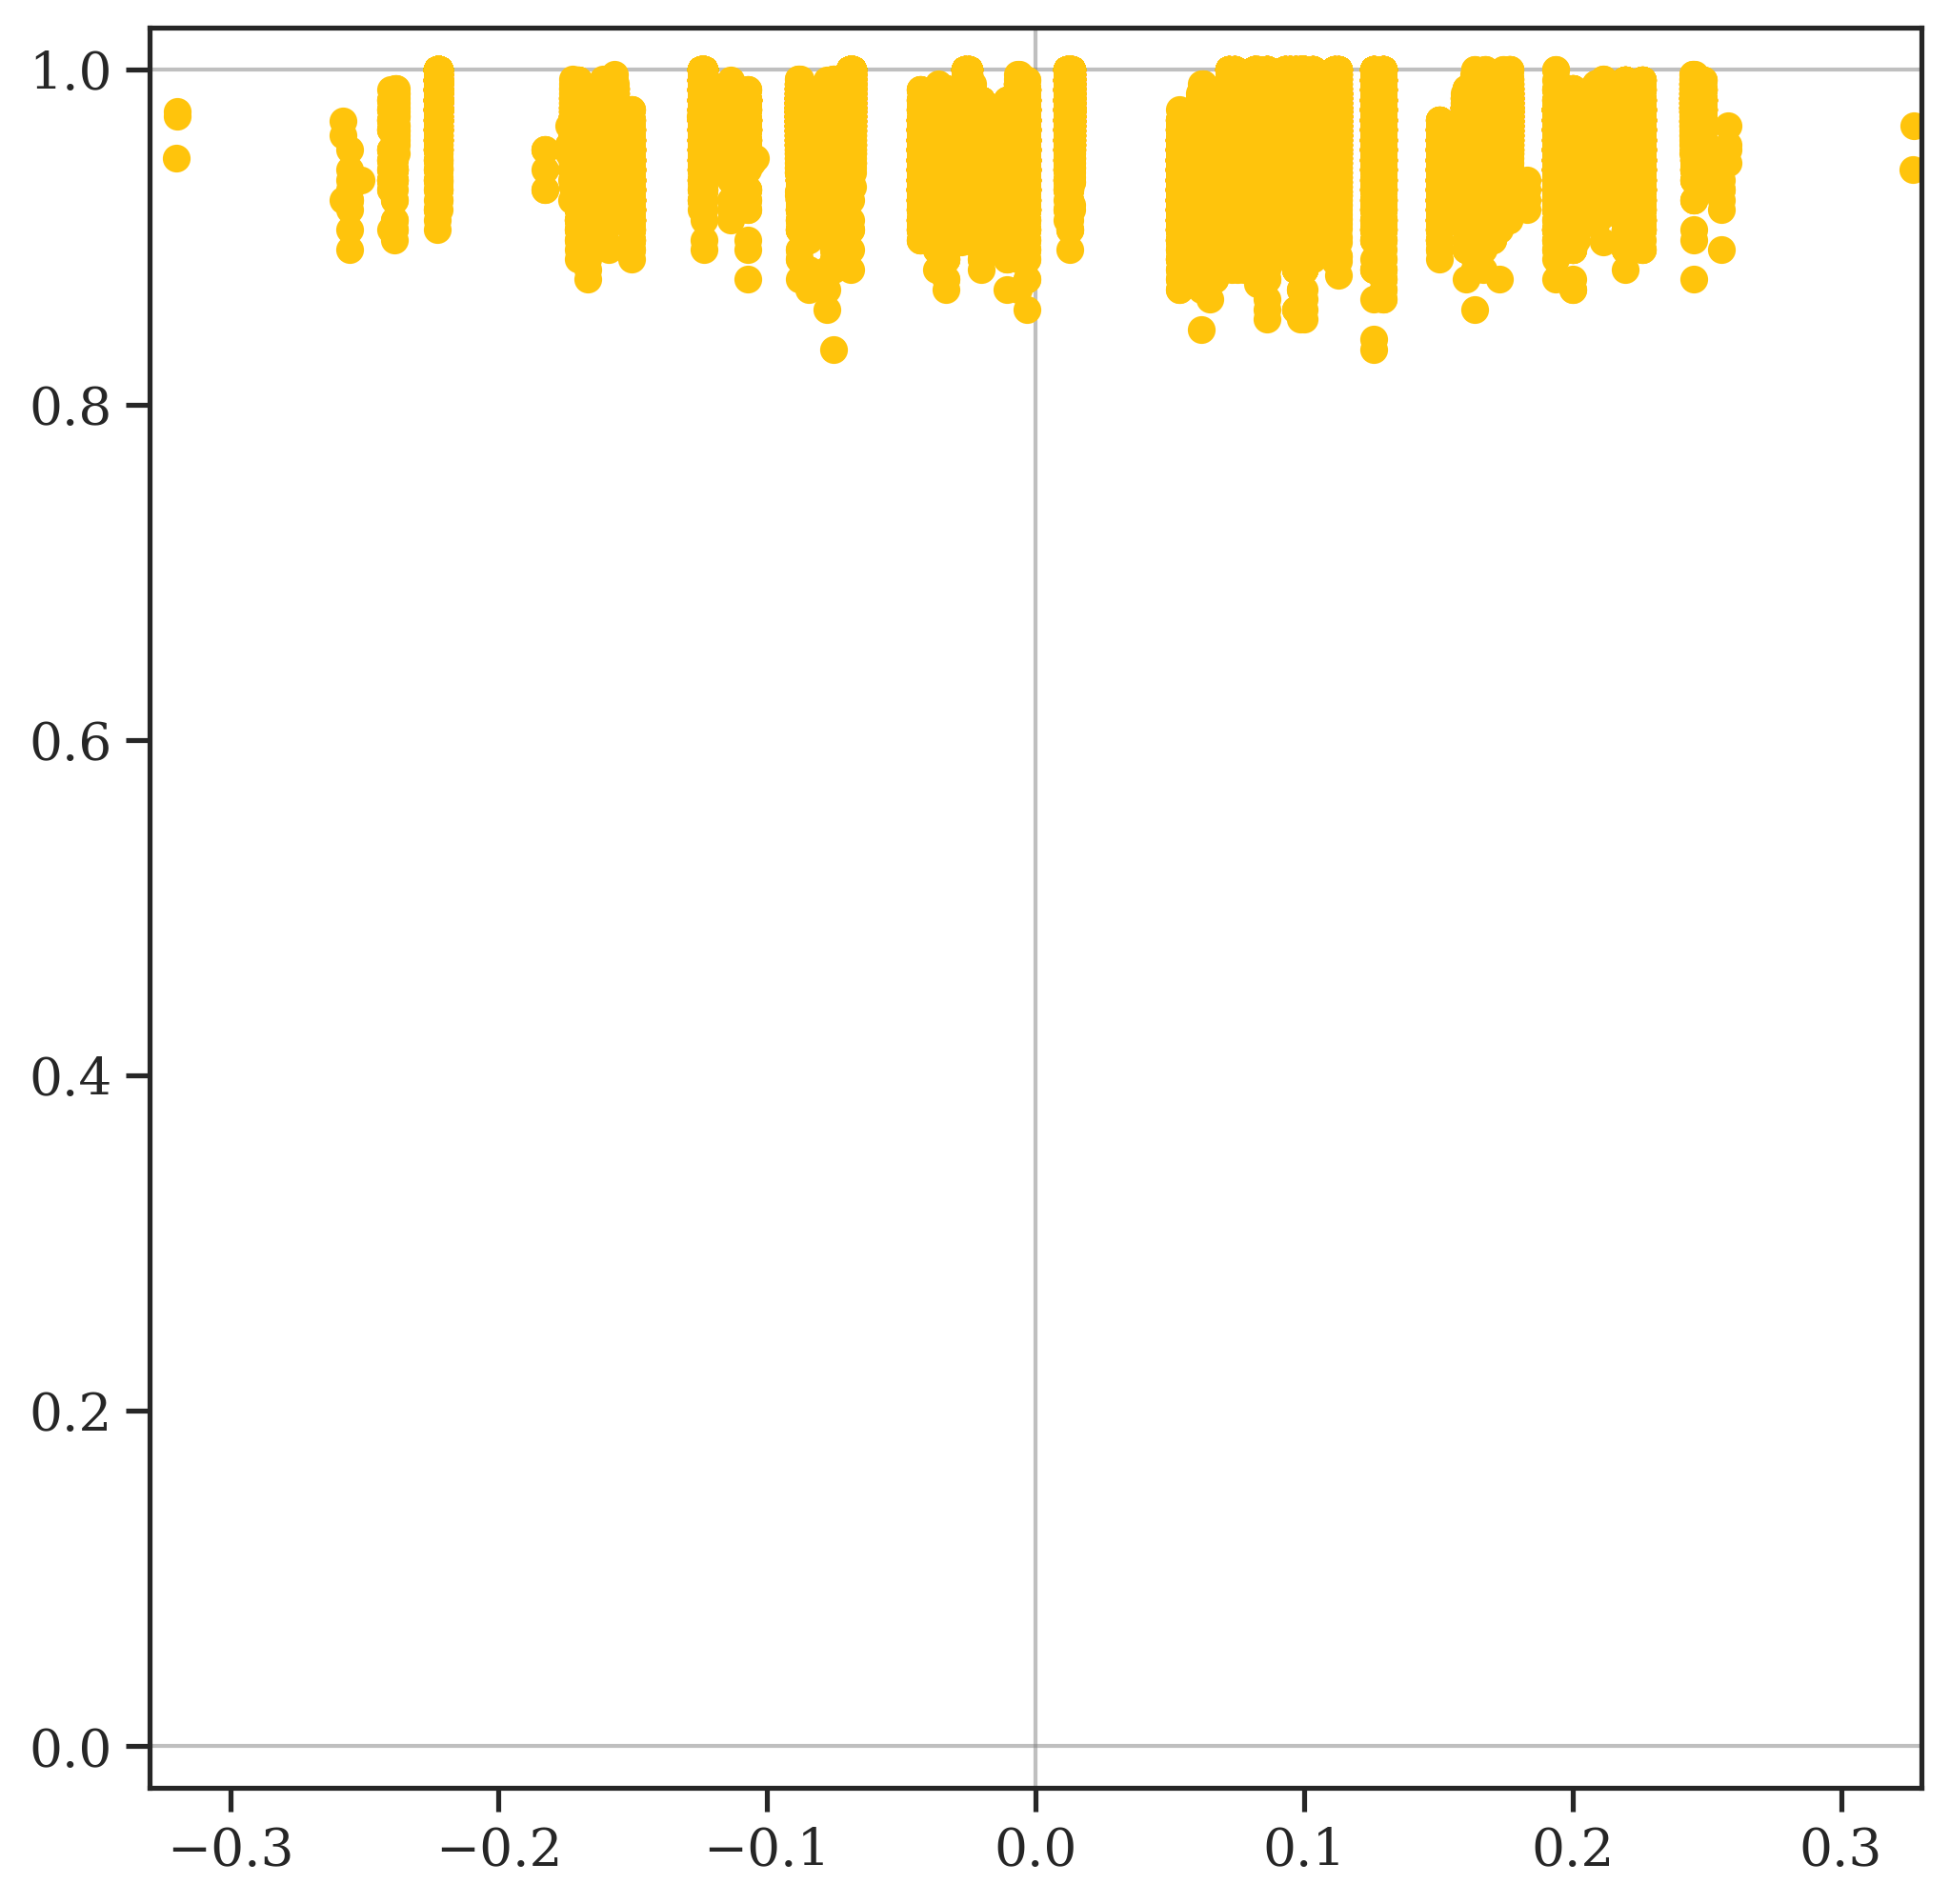

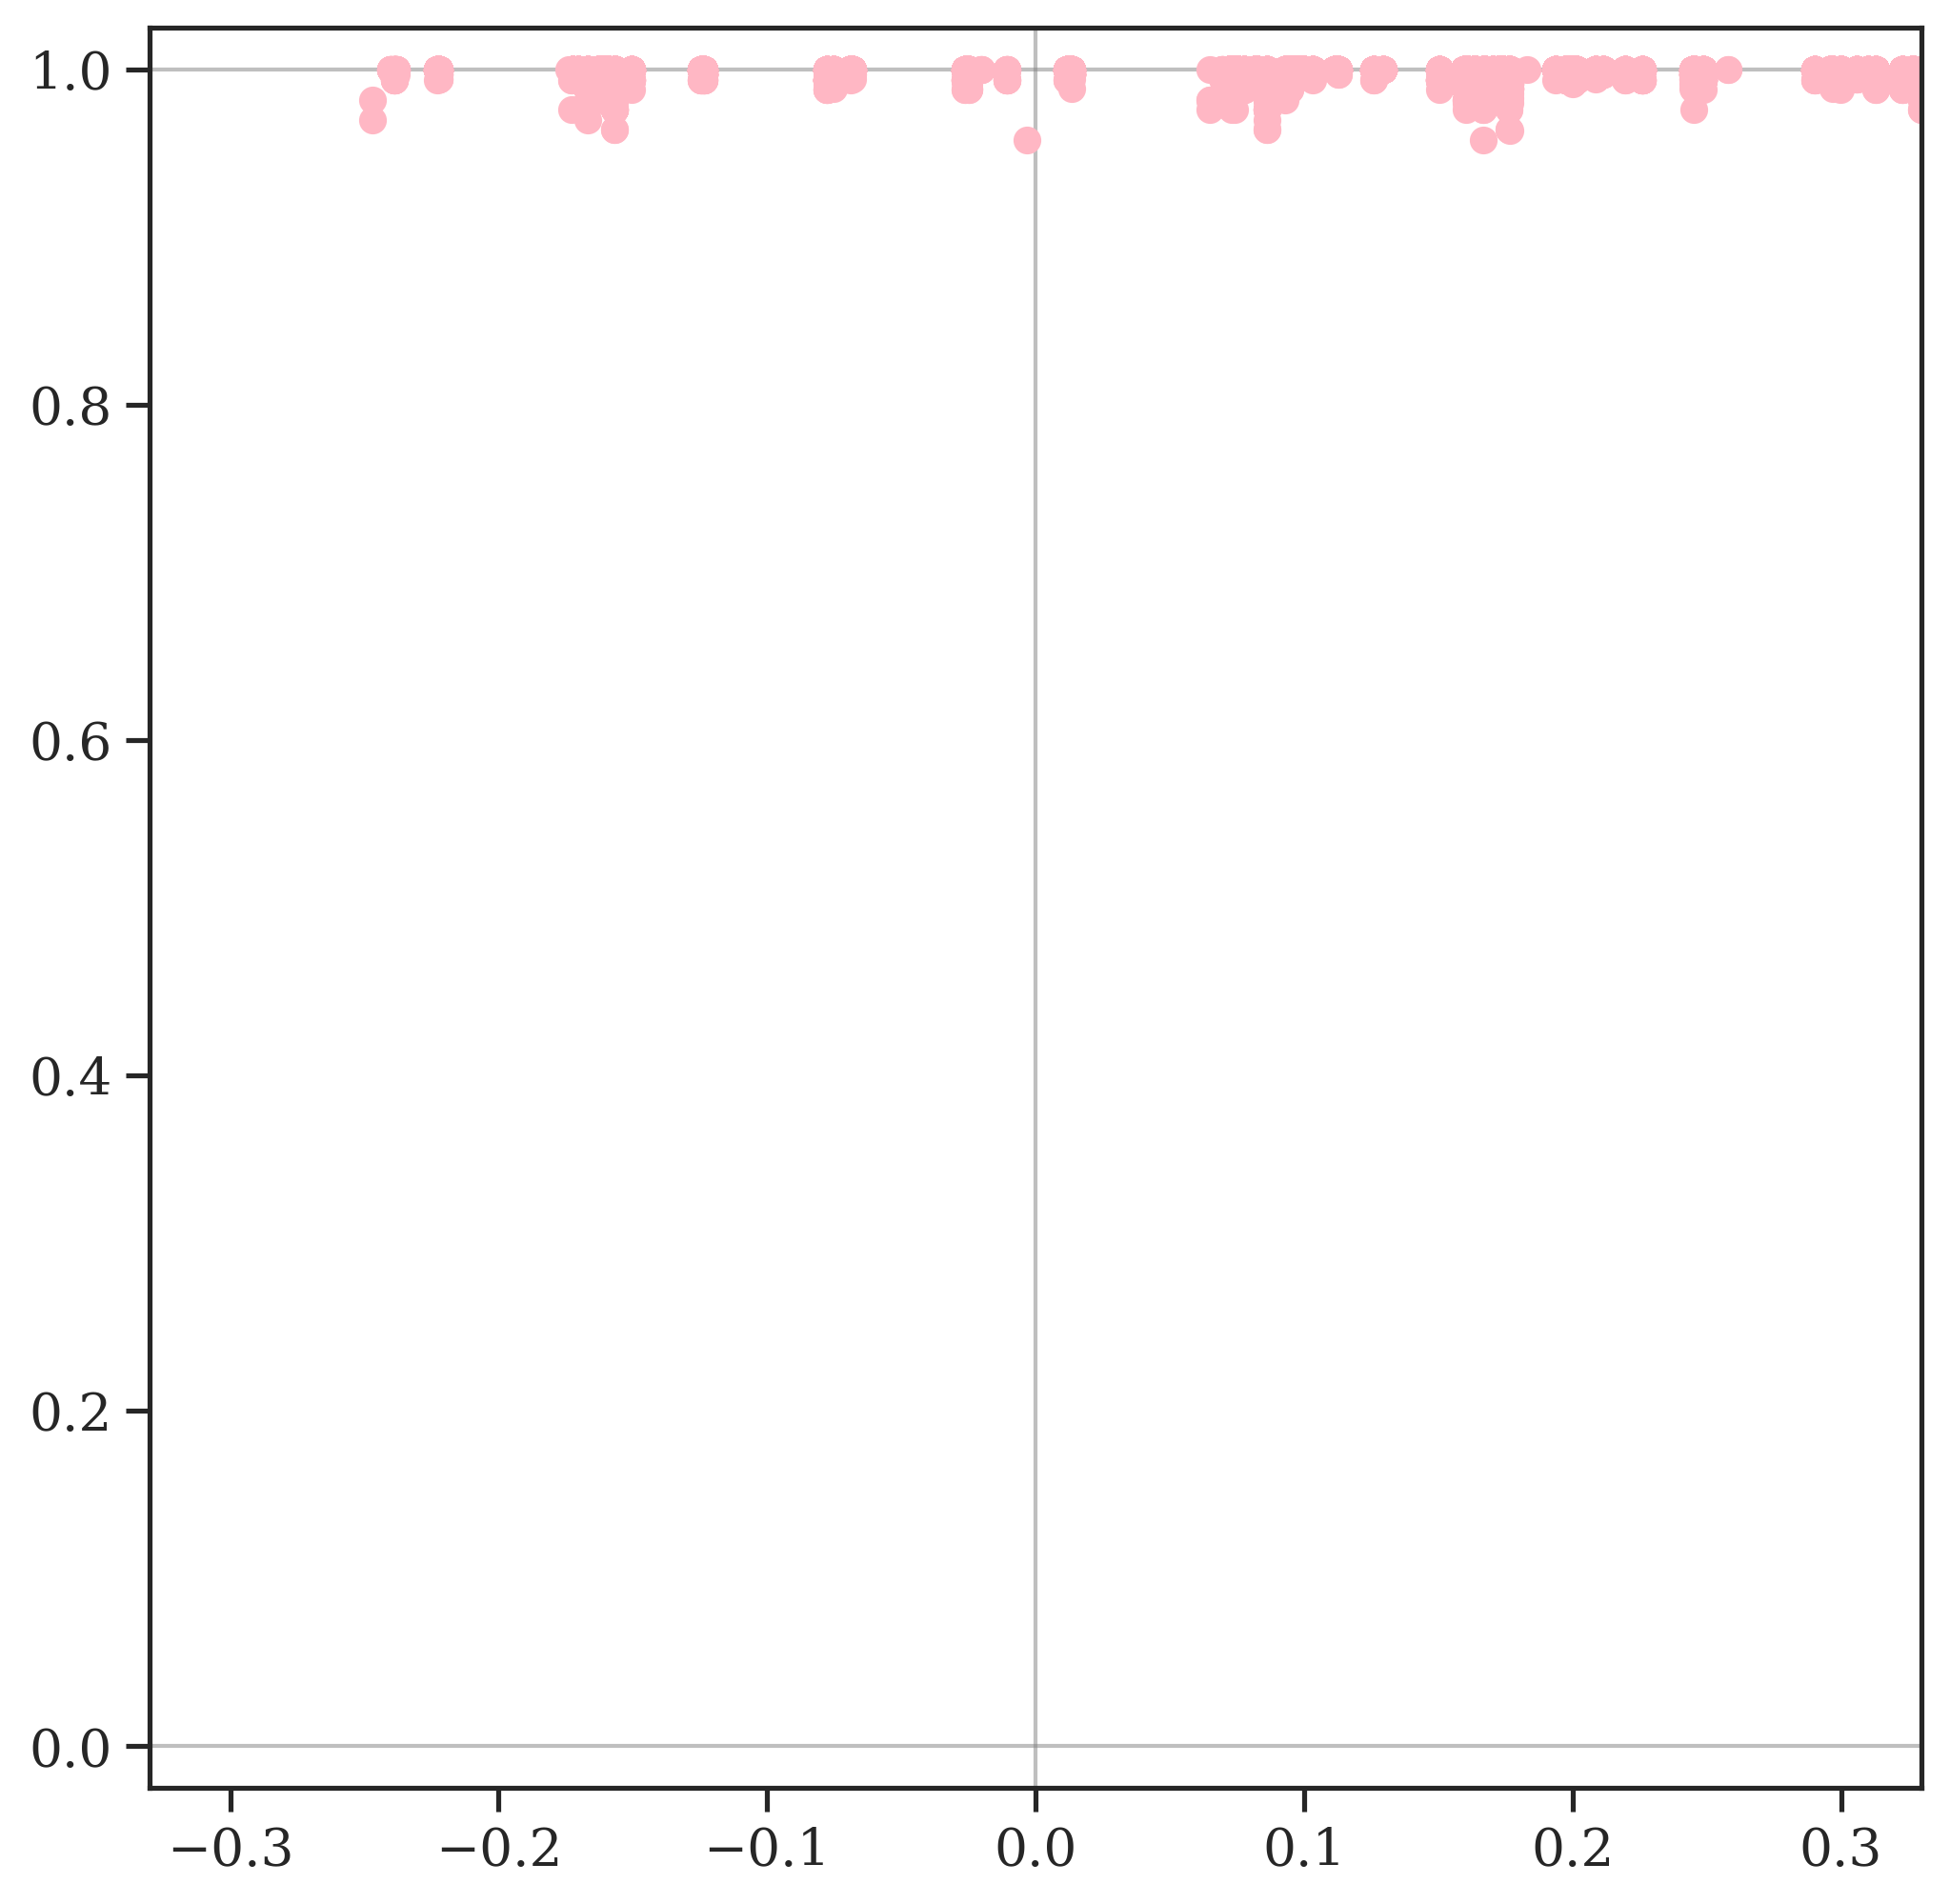

In [11]:
from pathlib import Path

output_dir = Path("../plots/bt_plots/prop_v_iia_plots/")
output_dir.mkdir(parents=True, exist_ok=True)
full_df_iia = iia_df.join(prop_df)

for voting_rule in voting_rule_names:
    _, ax = plt.subplots(figsize = (8,8), dpi=300)

    x_data = full_df_iia.loc[voting_rule]["prop"]
    y_data = full_df_iia.loc[voting_rule]["sigma_IIA"]
    ax.plot(
        x_data,
        y_data,
        marker='o',
        linestyle='',
        color=rule_color_map[voting_rule],
        label=voting_rule,
    )
    eps = 0.025
    sns.set_theme(style="ticks", context="notebook", font="serif", font_scale=1.2)
    # ax.set_xlim(-eps, 1.0 + eps)
    # FIXME: This is for disprop
    ax.set_xlim(-0.33, 0.33)
    ax.set_ylim(-eps, 1.0 + eps)
    # ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    # ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    # ax.set_xticklabels(["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"], fontdict={"family": "serif", "size": 12})
    # ax.set_yticklabels(["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"], fontdict={"family": "serif", "size": 12})
    for val in [0.0, 1.0]:
        ax.axhline(
            y=val,
            color="grey",
            linestyle="-",
            linewidth=1,
            zorder=-1,
            alpha=0.5,
        )
        ax.axvline(
            x=val,
            color="grey",
            linestyle="-",
            linewidth=1,
            zorder=-1,
            alpha=0.5,
        )
    # plt.savefig(output_dir / f"{voting_rule}_prop_v_iia.png", bbox_inches='tight', dpi=300)

    
    

In [9]:

output_base_dir = "preference_profiles"
um_data_base_dir = "../stats/bt_2_bloc_profile_stats/3_seats/sigma_UM"


df_list = []
for (n_a_cands, n_b_cands), (aa_alpha, ab_alpha, ba_alpha, bb_alpha), (a_cohesion, b_cohesion), b_proportion, voting_rule_name in product(
    candidate_count_combinations,
    alpha_combinations,
    cohesion_combinations,
    b_bloc_proportions,
    voting_rule_names
):
    profile_pattern = (
        f"{output_base_dir}/"
        f"{n_a_cands:02d}_{n_b_cands:02d}/"
        f"b_proportion_{b_proportion}"
        f"__ALPHA_({aa_alpha:.2f},{ab_alpha:.2f},{ba_alpha:.2f},{bb_alpha:.2f})"
        f"__COHESION_({a_cohesion:.2f},{b_cohesion:.2f})/"
    )

    um_pattern = (
        f"{um_data_base_dir}/"
        f"{n_a_cands+n_b_cands:02d}/"
        f"{voting_rule_name}/"
        "METRIC_sigma_UM__VARIANT_worst_case__INTERP_asin"
        f"__NCANDS_({n_a_cands:02d}_{n_b_cands:02d})"
        "__SEATS_3"
        f"__BPROP_{b_proportion:0.1f}"
        f"__ALPHA_({aa_alpha:0.2f},{ab_alpha:0.2f},{ba_alpha:0.2f},{bb_alpha:0.2f})"
        f"__COHESION_({a_cohesion:.2f},{b_cohesion:.2f})"
        f"__TYPE_{voting_rule_name}"
        "__TIEBREAK_lex.json"
    )    

    with open(um_pattern, "r") as f:
        um_data = json.load(f)
    df_data = []
    for file, value in zip(profile_ordering, um_data):
        df_data.append({
            "file": f"{profile_pattern}{file}",
            "method": voting_rule_name,
            "sigma_IIA": value,
        })

    df_list.append(pd.DataFrame(df_data))


um_df = pd.concat(df_list, ignore_index=True)
um_df.set_index(["method", "file"], inplace=True)
um_df

sigma_IIA
method       file                                                         
borda        preference_profiles/02_06/b_proportion_0.5__ALP...   0.925223
             preference_profiles/02_06/b_proportion_0.5__ALP...   1.000000
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.889674
             preference_profiles/02_06/b_proportion_0.5__ALP...   1.000000
             preference_profiles/02_06/b_proportion_0.5__ALP...   0.852587
...                                                                    ...
ranked-pairs preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000
             preference_profiles/08_02/b_proportion_0.9__ALP...   1.000000

[504000 rows x 1 columns]

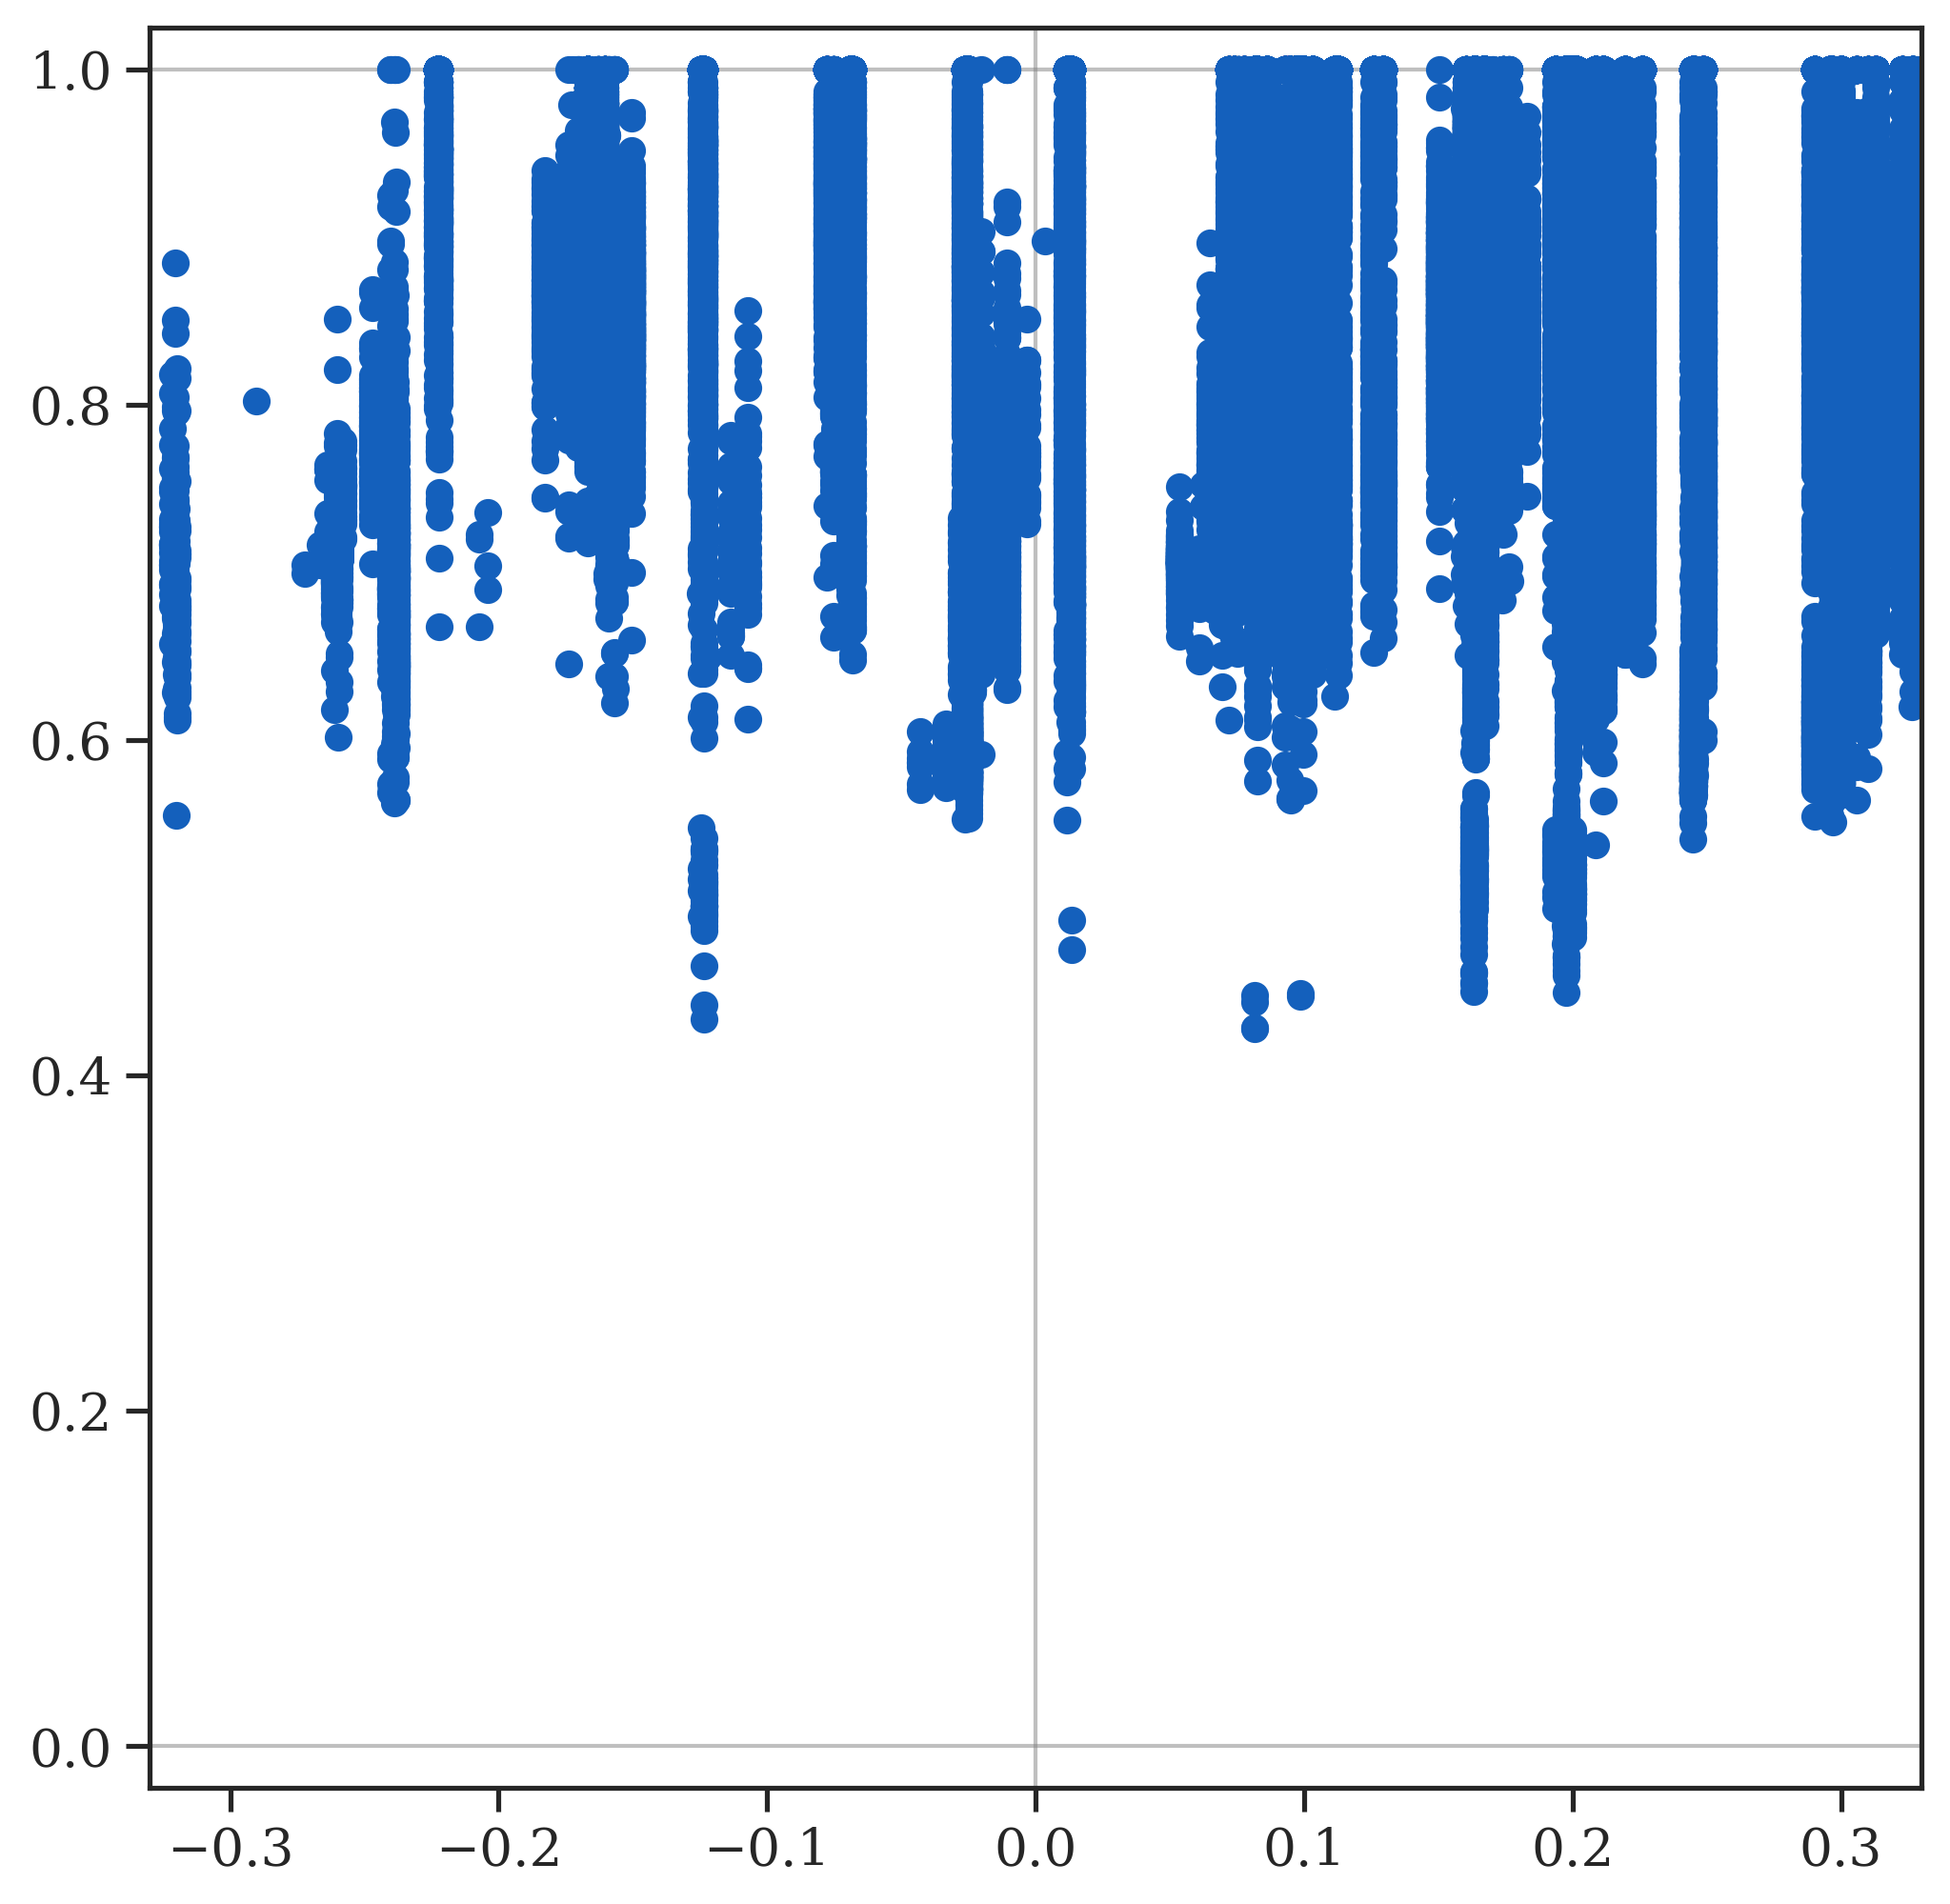

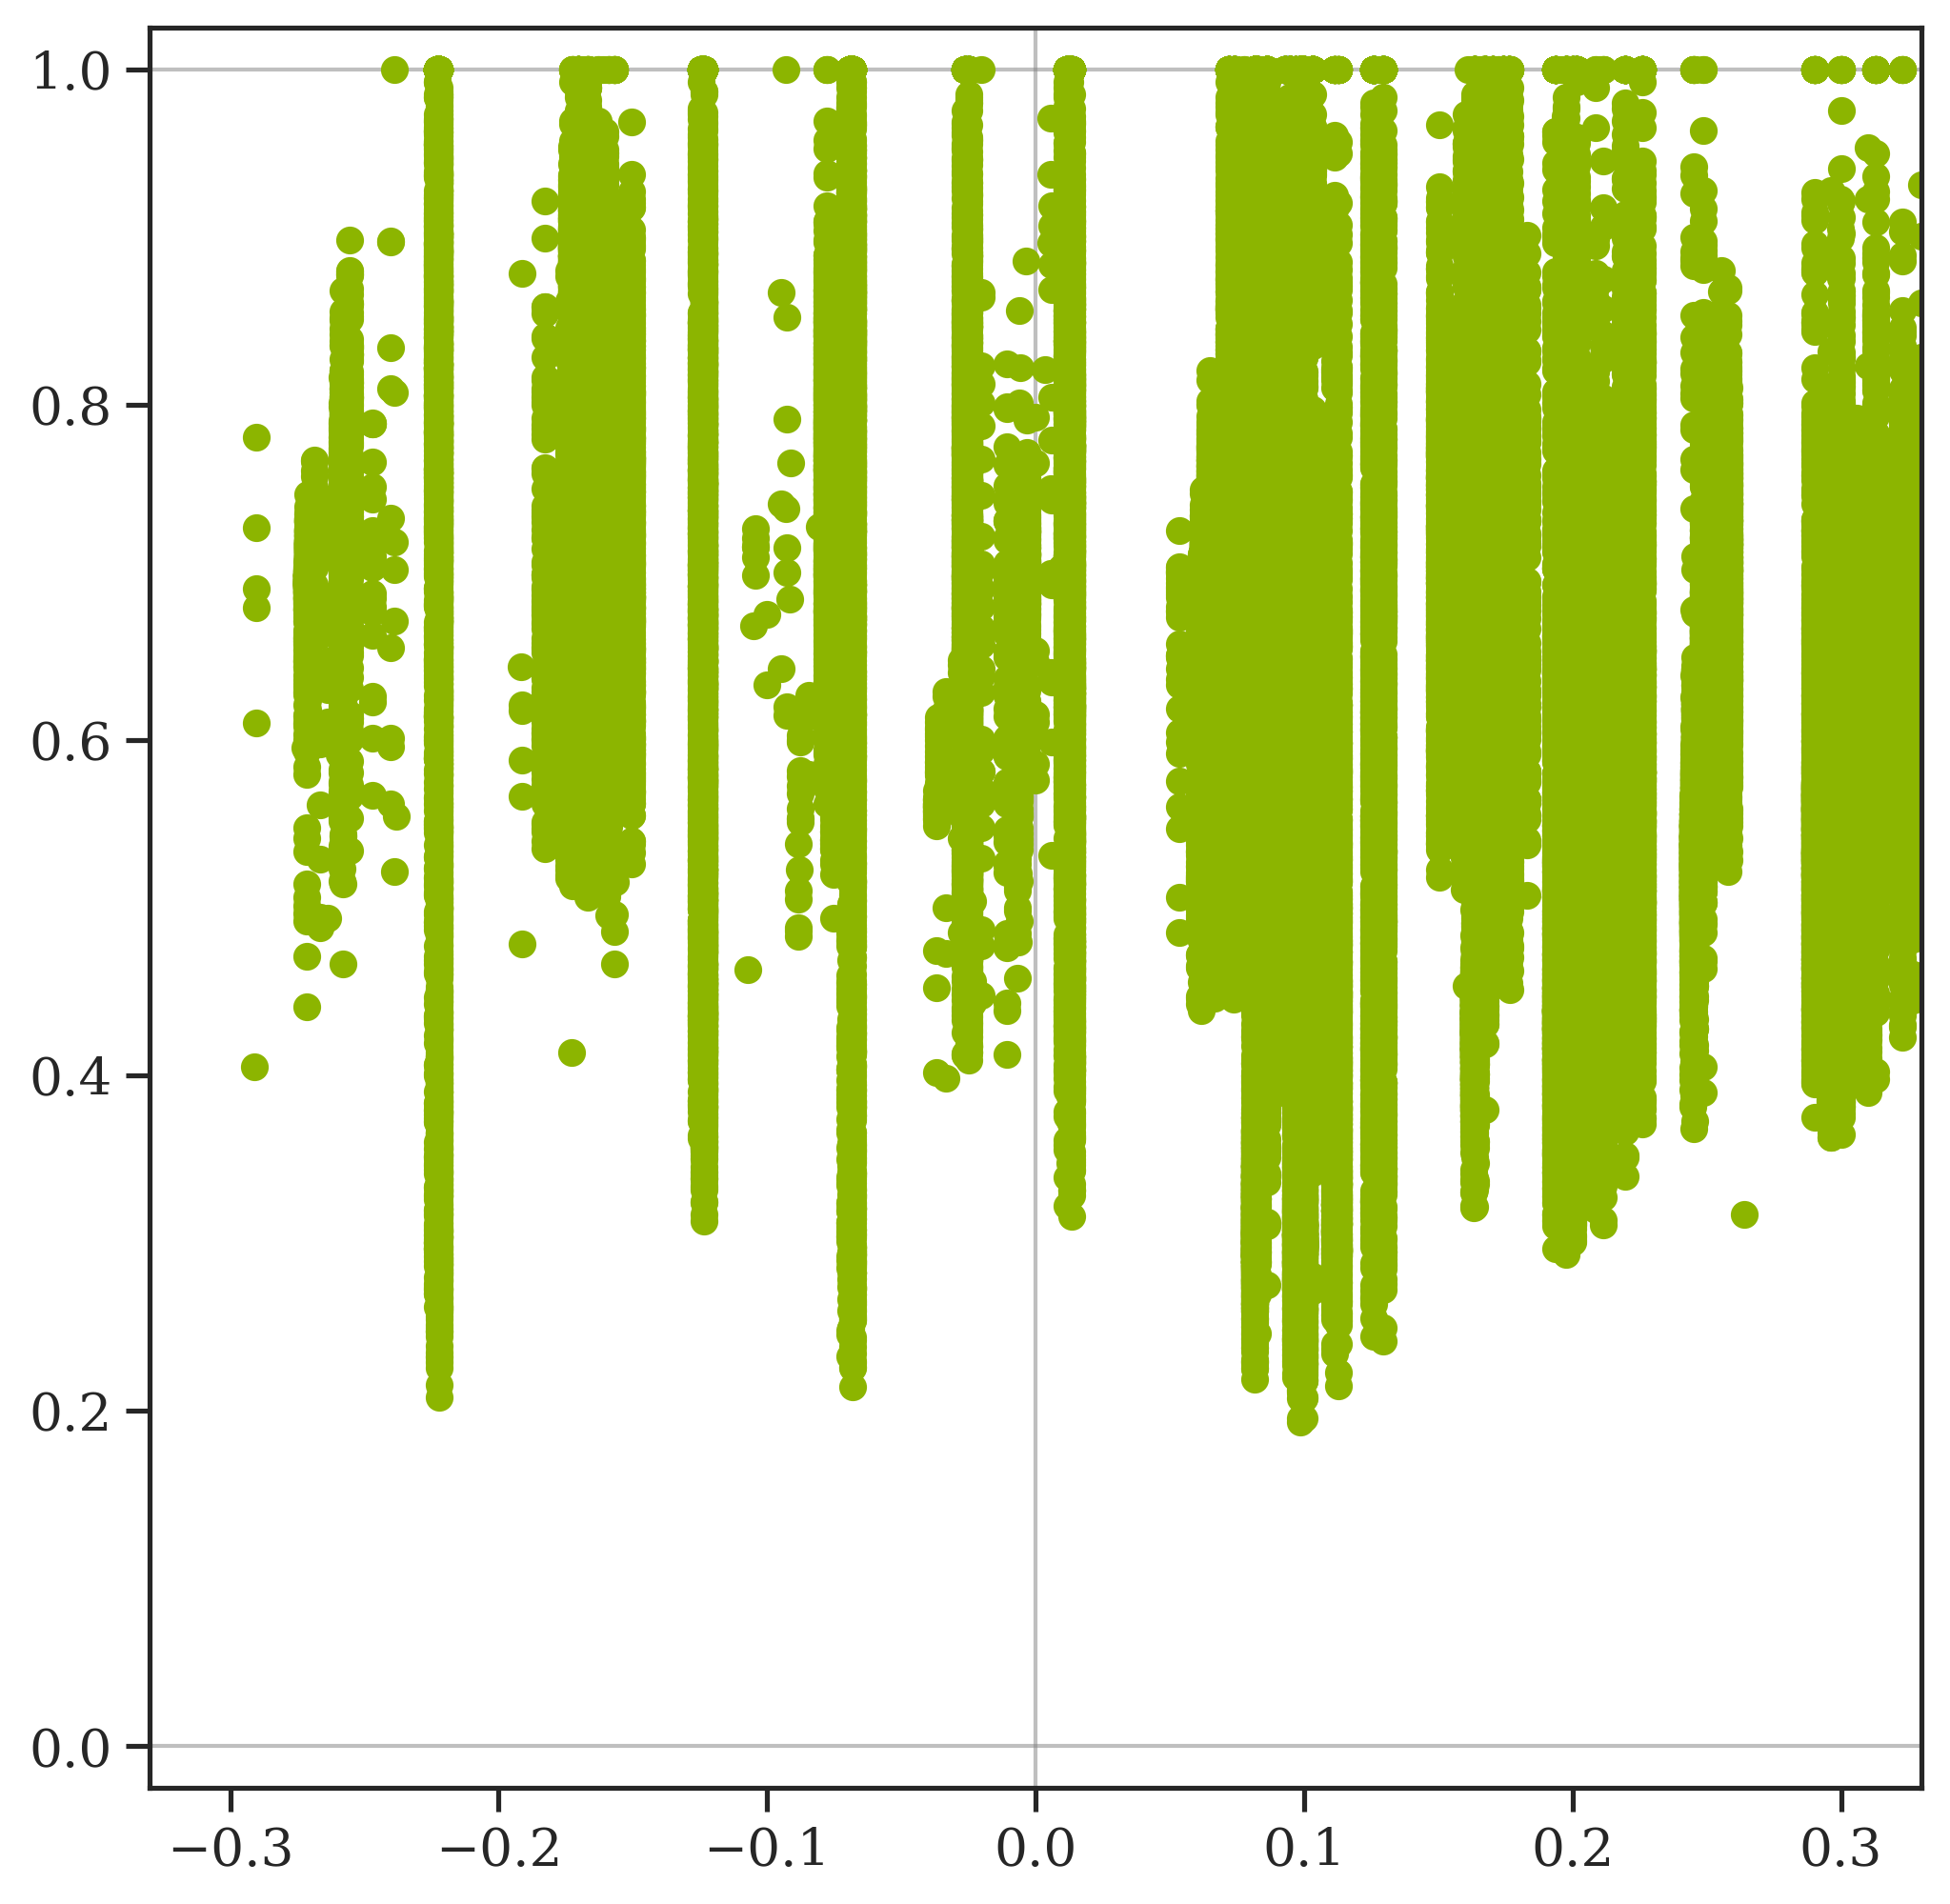

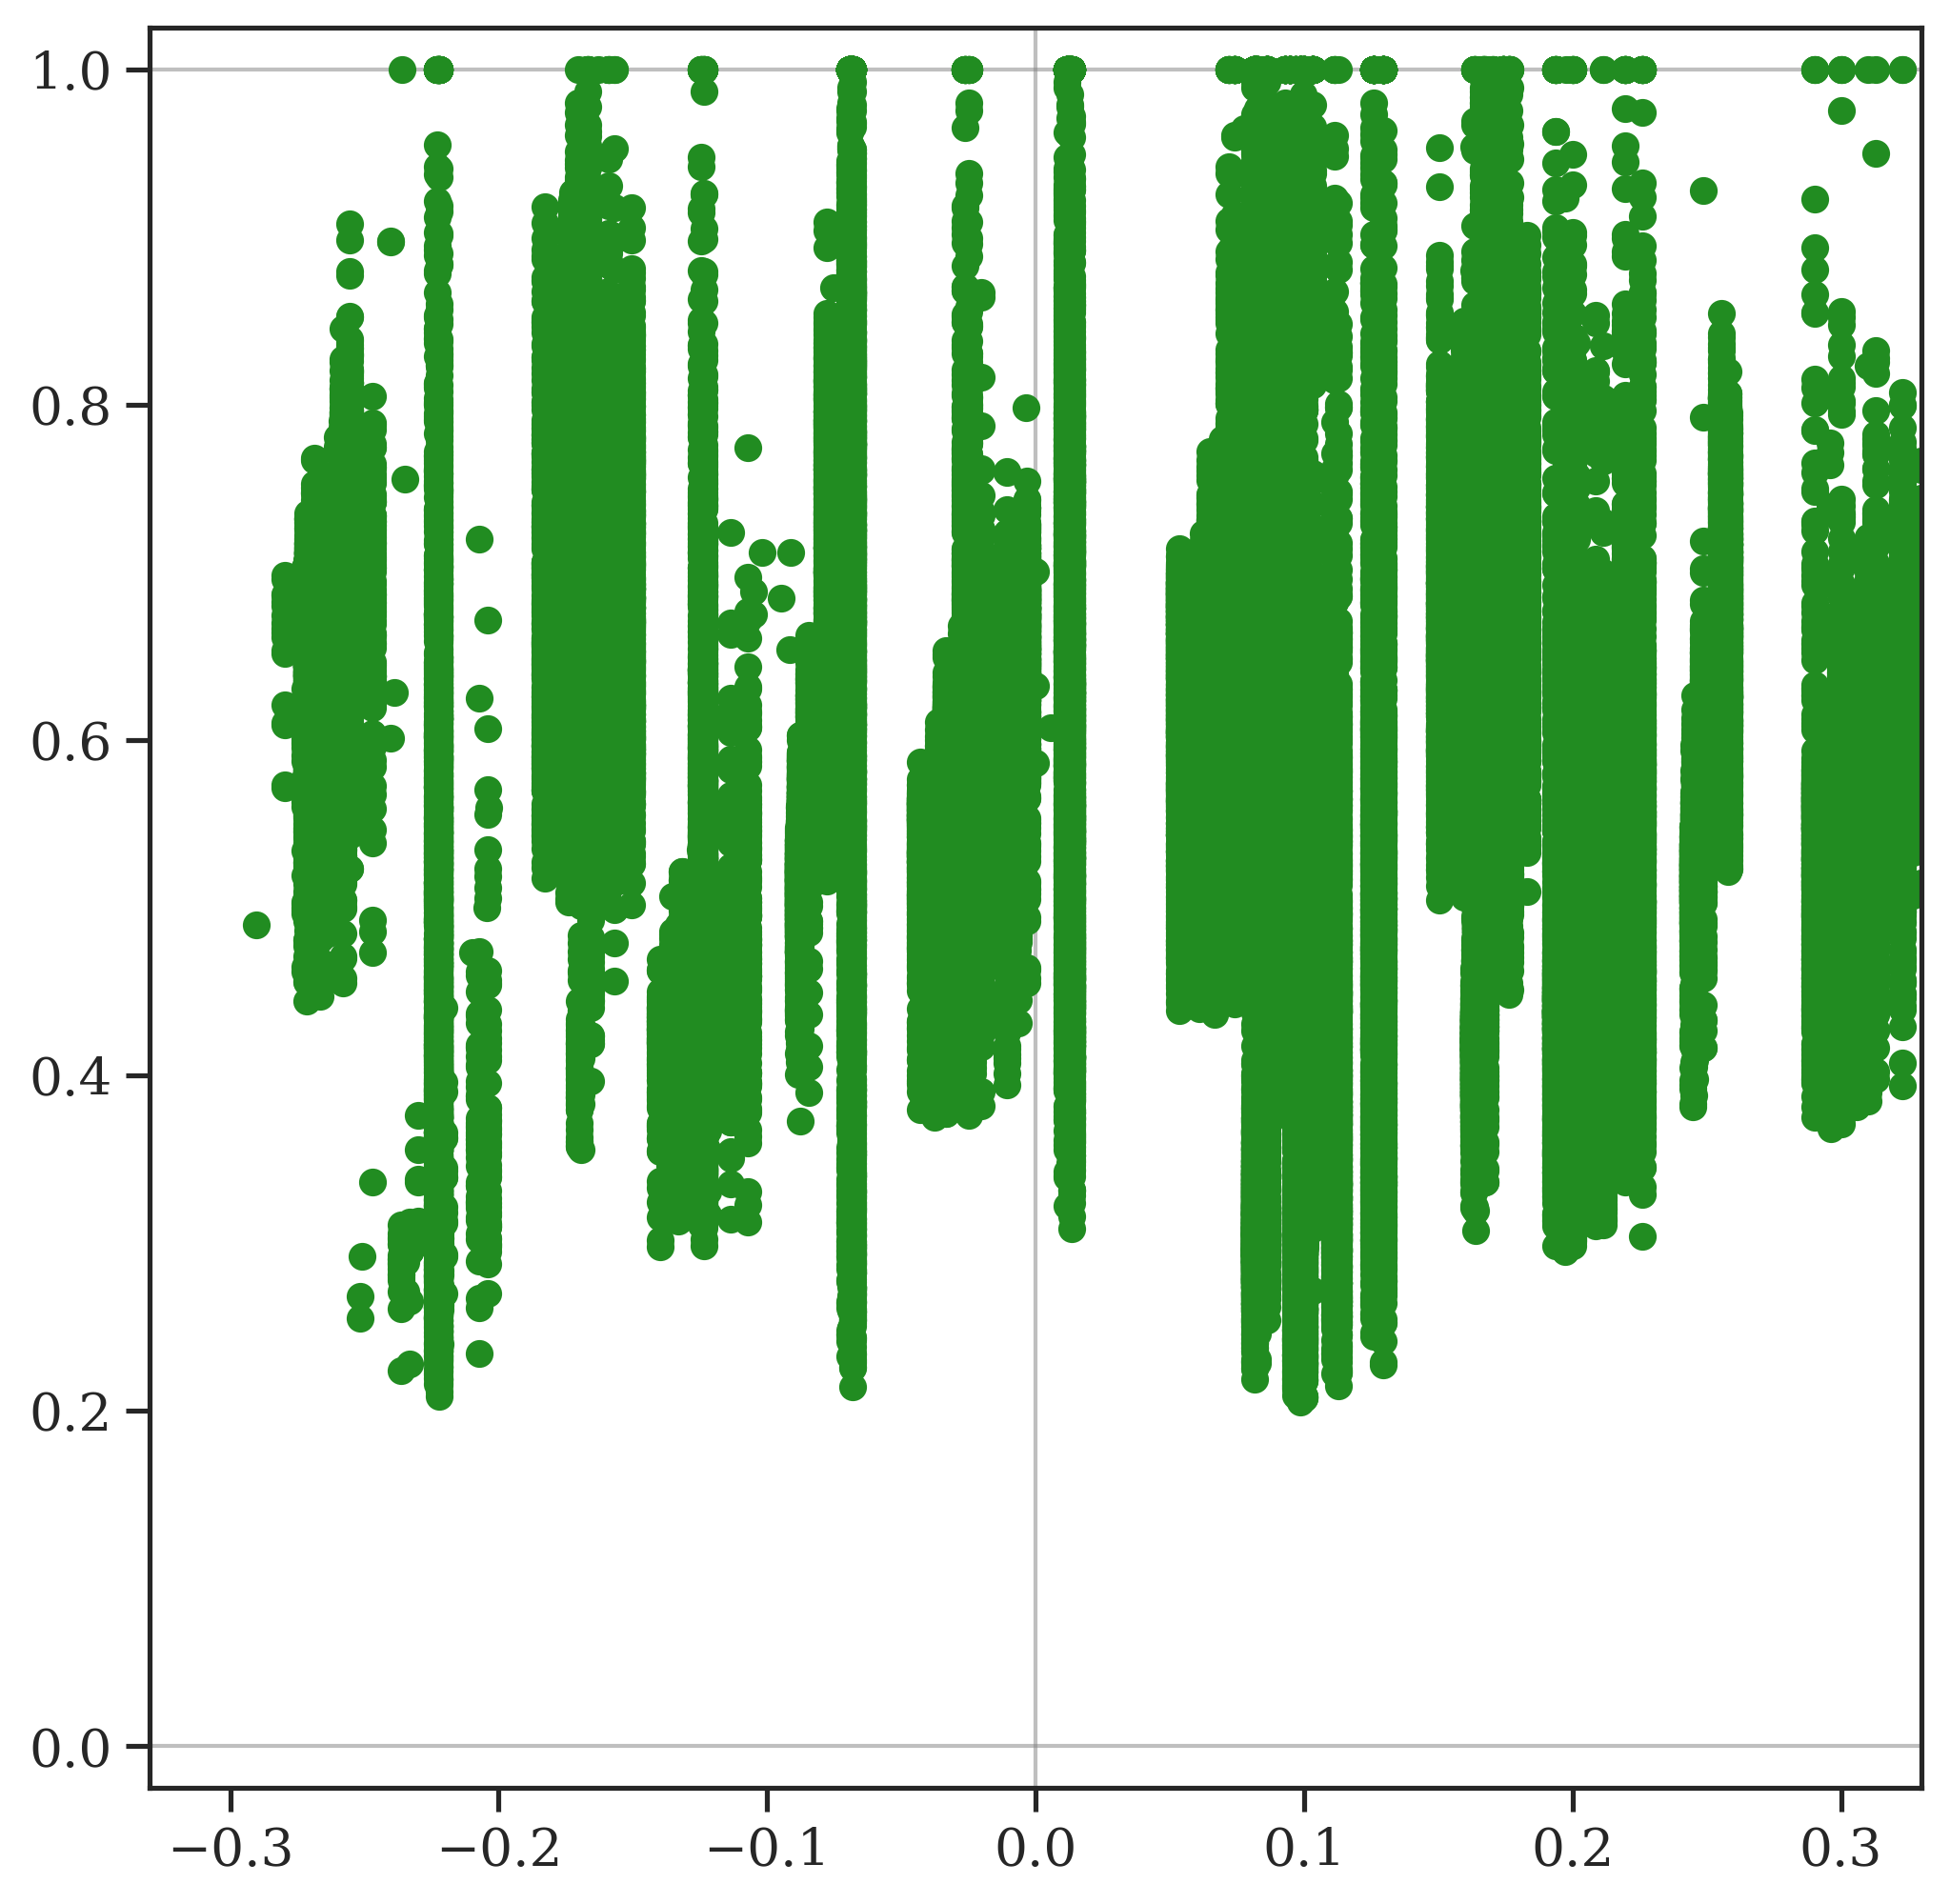

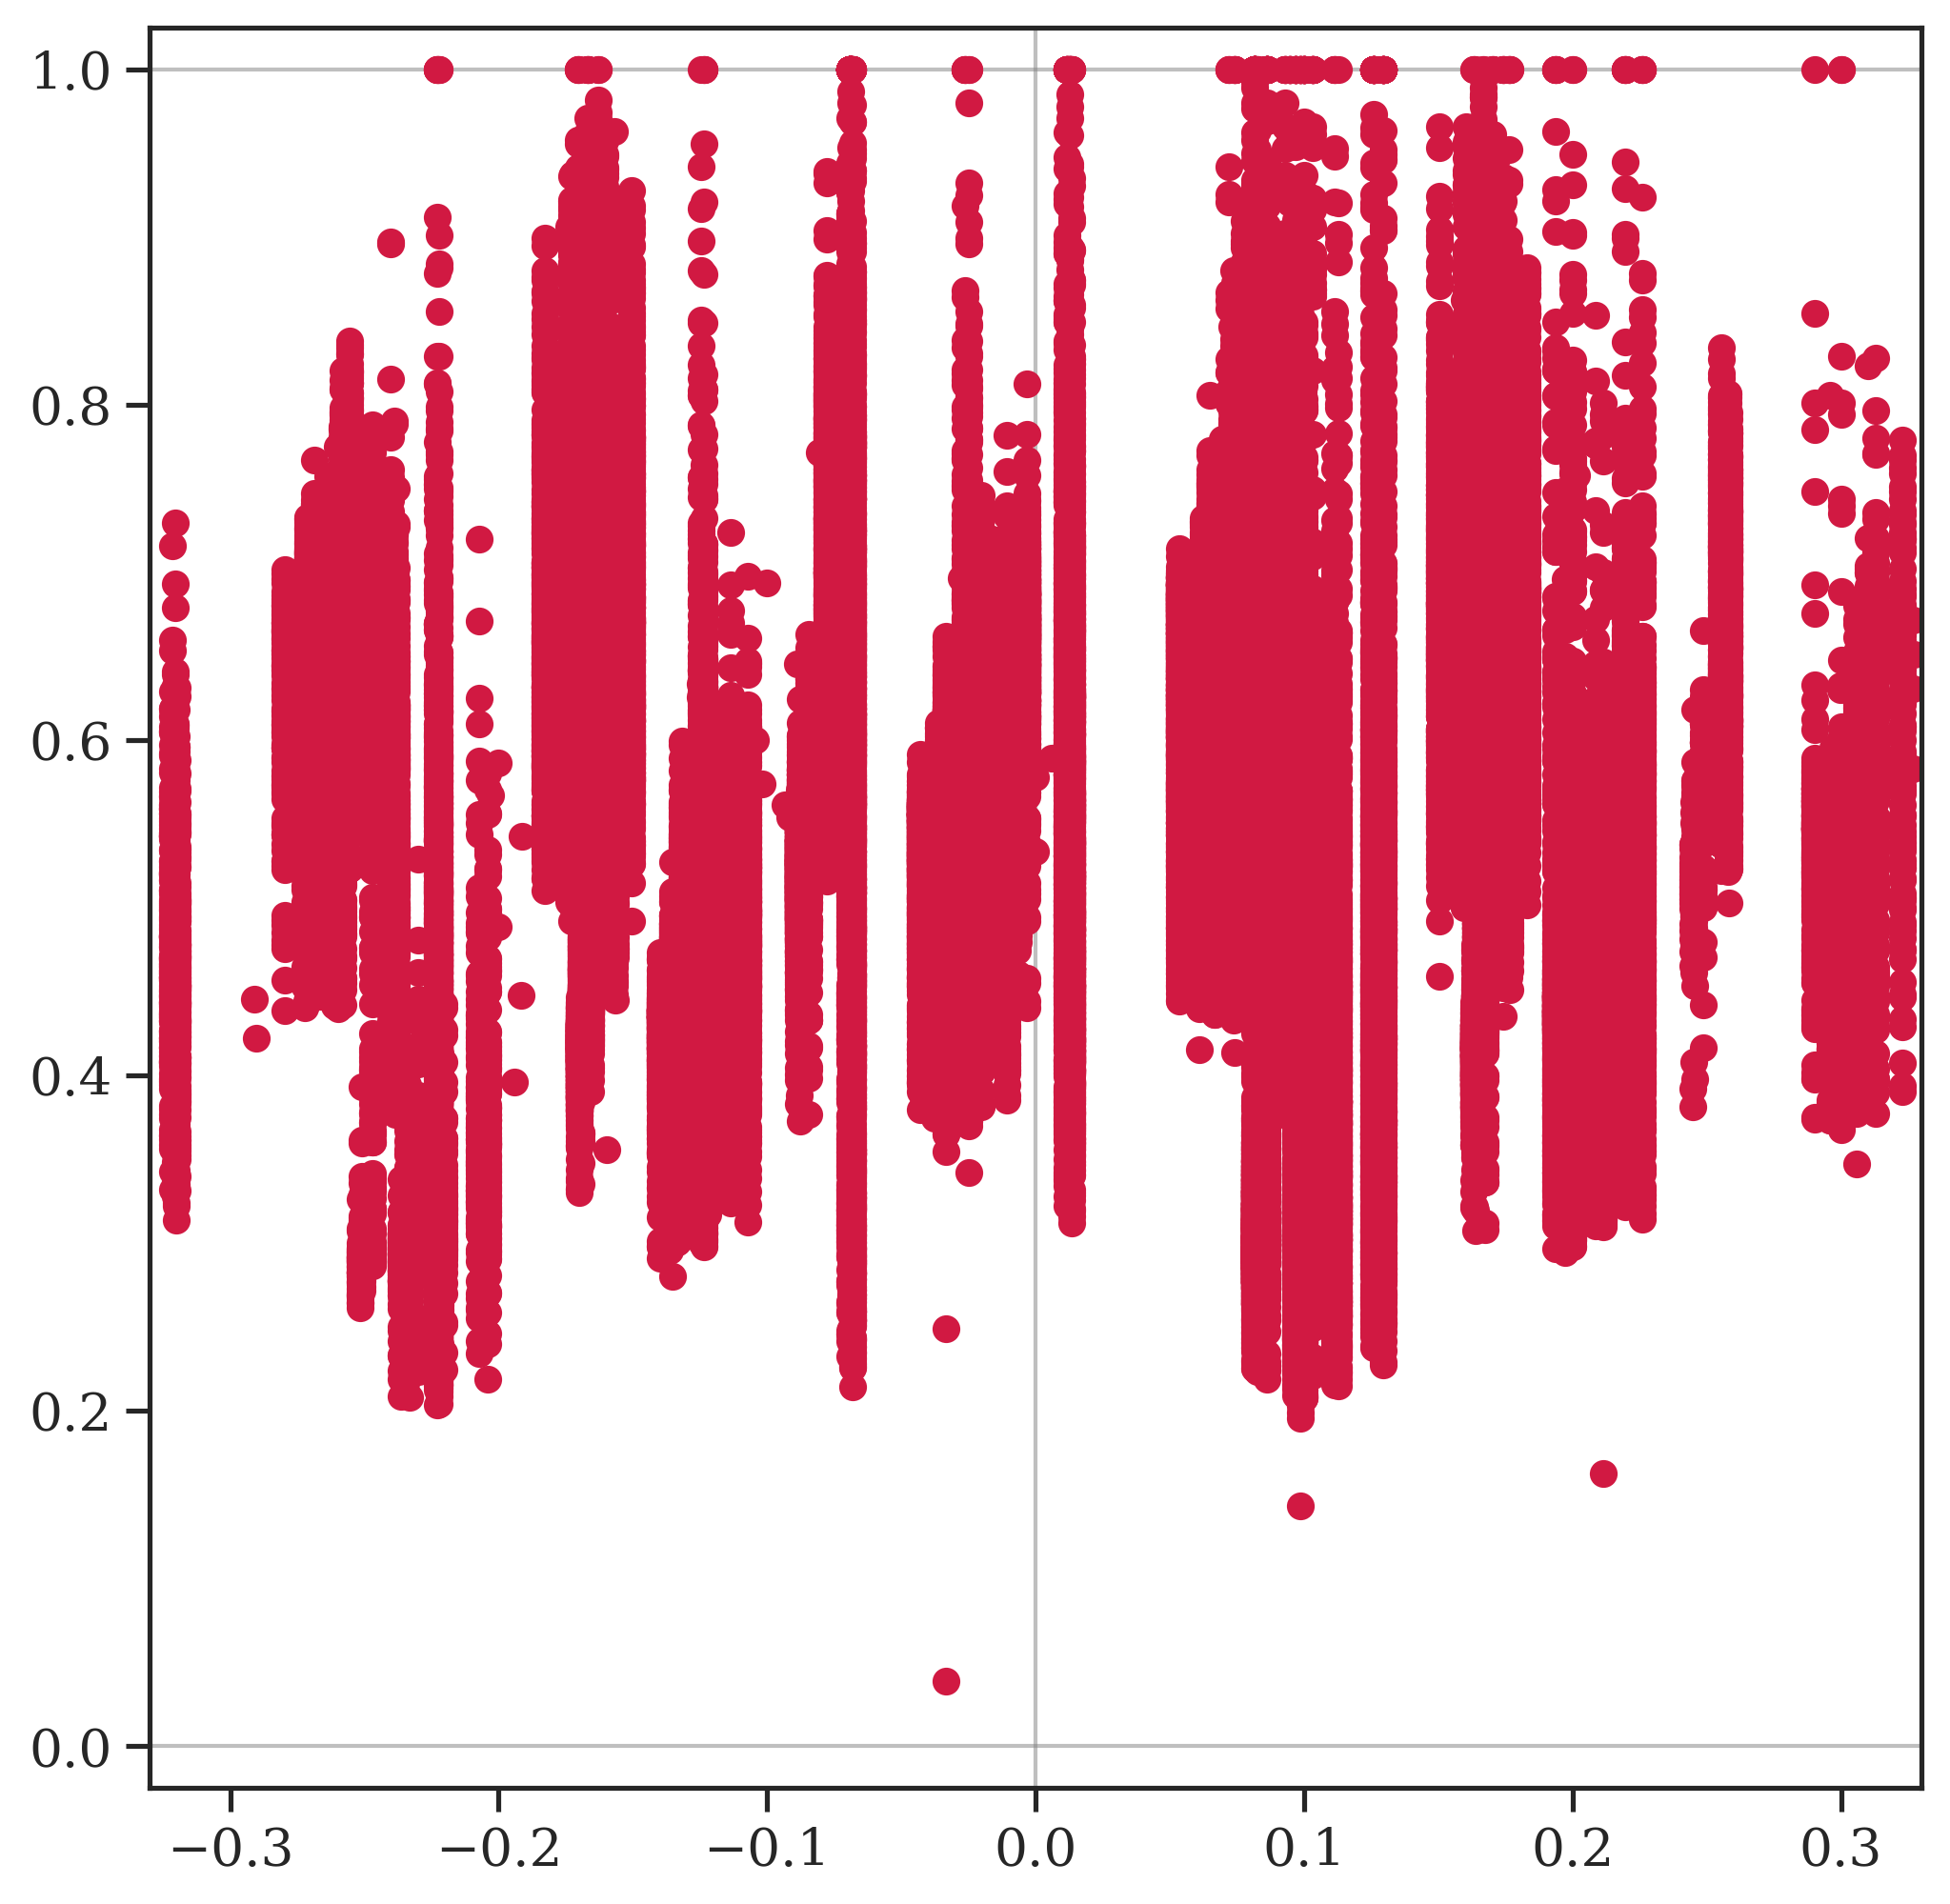

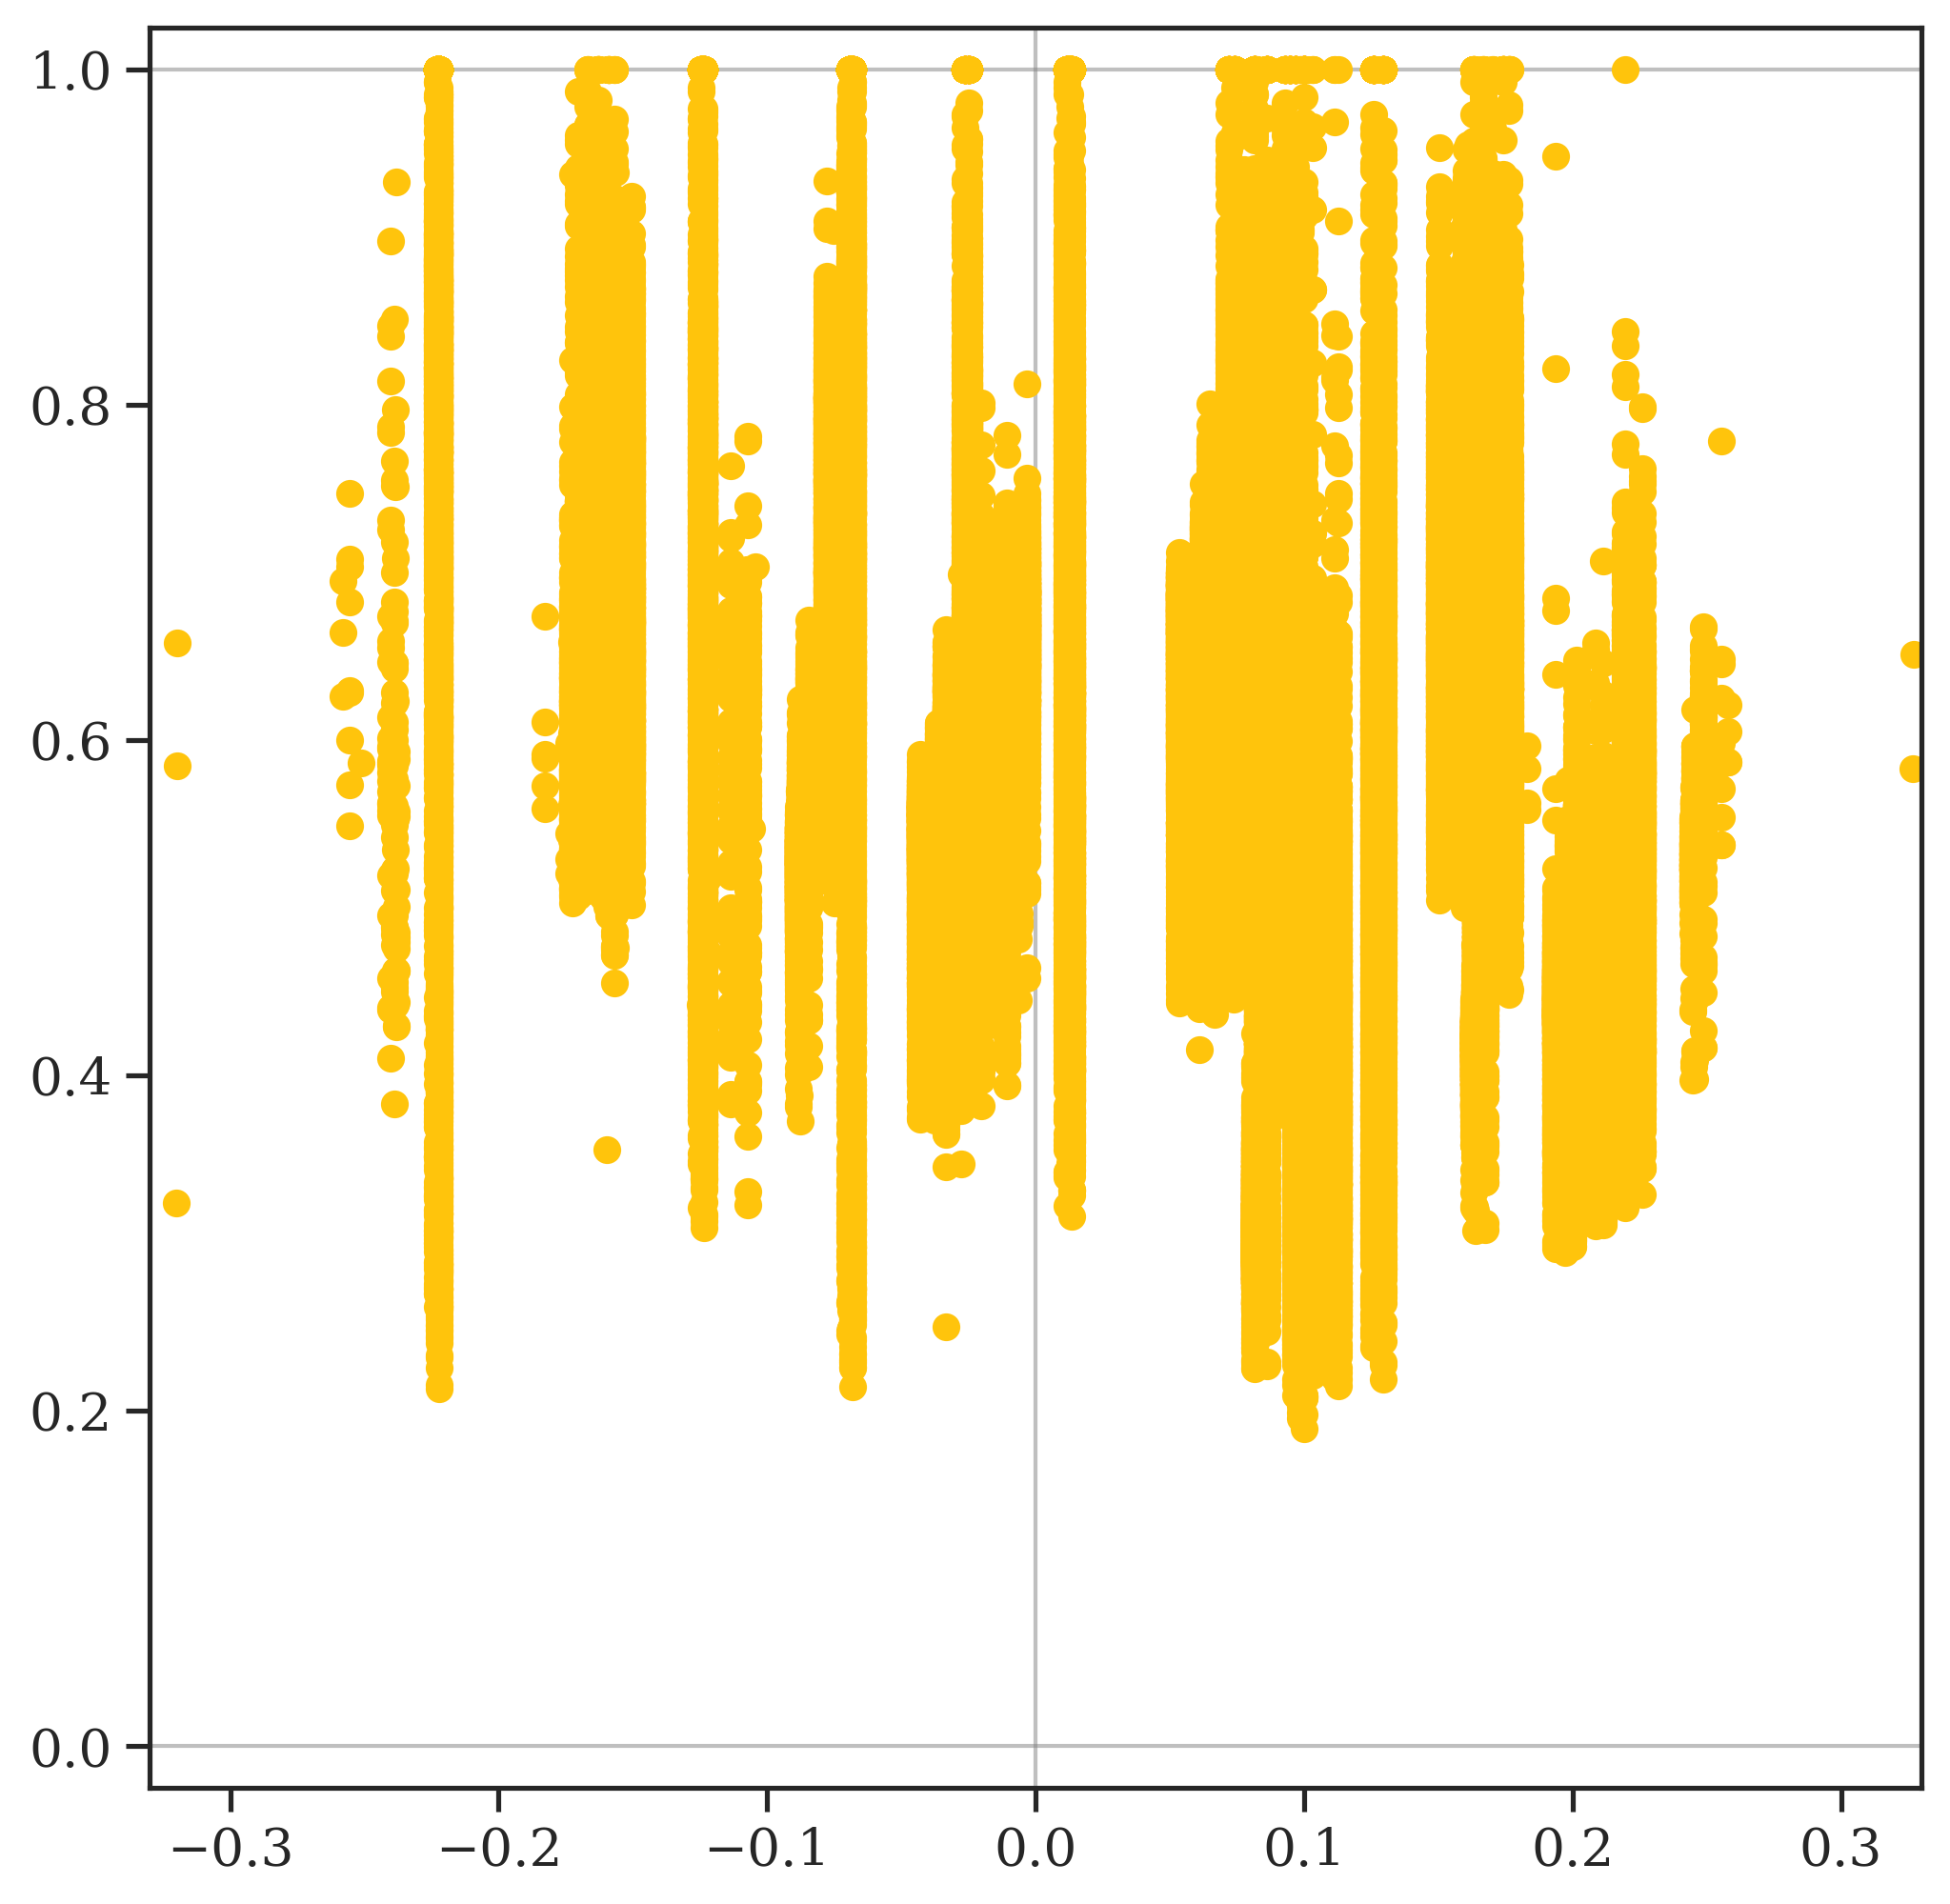

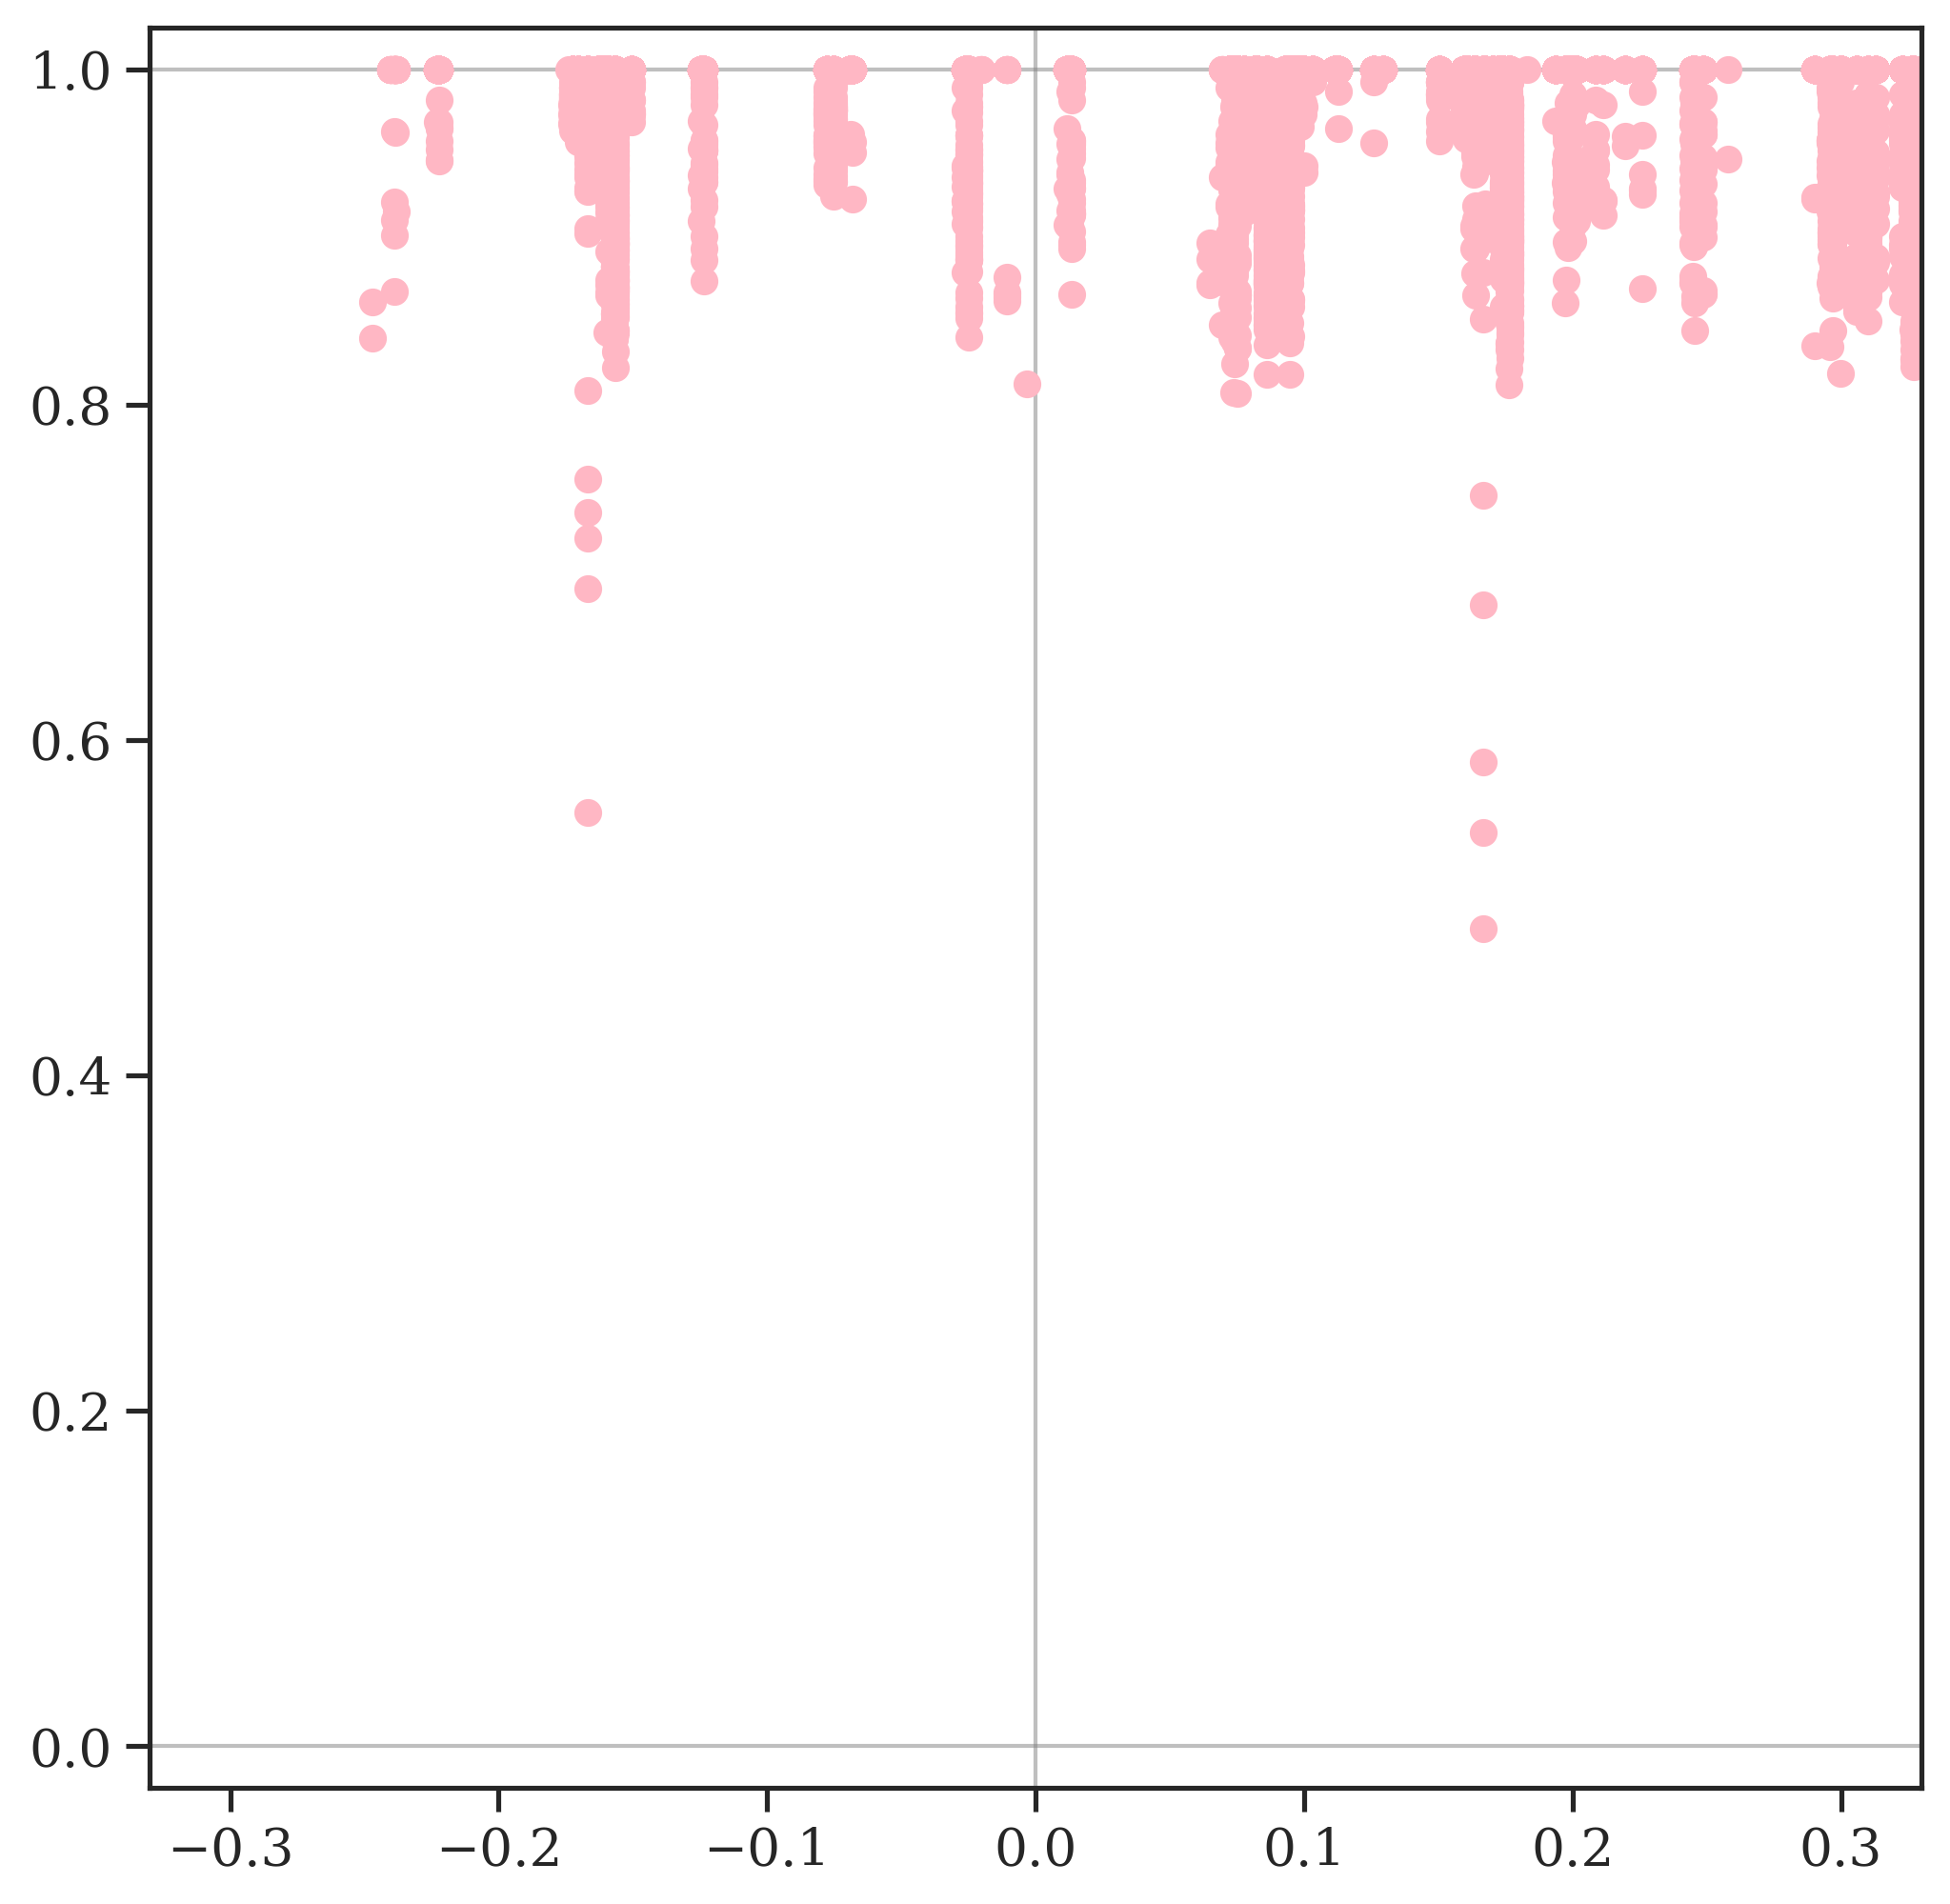

In [13]:
output_dir = Path("../plots/bt_plots/prop_v_um_plots/")
output_dir.mkdir(parents=True, exist_ok=True)
full_df_um = um_df.join(prop_df)

for voting_rule in voting_rule_names:
    _, ax = plt.subplots(figsize = (8,8), dpi=300)

    x_data = full_df_um.loc[voting_rule]["prop"]
    y_data = full_df_um.loc[voting_rule]["sigma_IIA"]
    ax.plot(
        x_data,
        y_data,
        marker='o',
        linestyle='',
        color=rule_color_map[voting_rule],
        label=voting_rule,
    )
    eps = 0.025
    sns.set_theme(style="ticks", context="notebook", font="serif", font_scale=1.2)
    # ax.set_xlim(-eps, 1.0 + eps)
    # FIXME: This is for disprop
    ax.set_xlim(-0.33, 0.33)
    ax.set_ylim(-eps, 1.0 + eps)
    # ax.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    # ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    # ax.set_xticklabels(["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"], fontdict={"family": "serif", "size": 12})
    # ax.set_yticklabels(["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"], fontdict={"family": "serif", "size": 12})
    for val in [0.0, 1.0]:
        ax.axhline(
            y=val,
            color="grey",
            linestyle="-",
            linewidth=1,
            zorder=-1,
            alpha=0.5,
        )
        ax.axvline(
            x=val,
            color="grey",
            linestyle="-",
            linewidth=1,
            zorder=-1,
            alpha=0.5,
        )
    # plt.savefig(output_dir / f"{voting_rule}_prop_v_um.png", bbox_inches='tight', dpi=300)
